In [2]:
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt 

from pathlib import Path

In [ ]:
# dataset path and structure
DATA_DIR = Path("../data/raw/")

for file in sorted(DATA_DIR.iterdir()):
    print(file.name)

LICENSE-DATA
README.md
case_matrix.csv
cz_v2_doe.zip
cz_v2_holdout.zip
cz_v2_mesh_coarse.zip
cz_v2_mesh_fine.zip
doe_excluded_cases.csv
doe_run_status.csv
holdout_cases.csv
holdout_excluded_cases.csv
holdout_run_status.csv
mesh_study_fields.csv
mesh_study_quantities.csv
node_order_base_8181.csv
node_order_coarse_2091.csv
node_order_fine_32200.csv


In [4]:
# Read the case matrix
cases = pd.read_csv(DATA_DIR / "case_matrix.csv")

cases.head()

,case_id,group,crystal_rpm,crucible_rpm,t_hot
0,sobol_000,sobol,10.896472,-2.670688,1774.352702
1,sobol_001,sobol,17.917017,-6.062550,1757.430408
2,sobol_002,sobol,13.246647,-5.408550,1769.955855
3,sobol_003,sobol,6.189864,-7.851605,1731.750599
4,sobol_004,sobol,4.694309,-3.565196,1749.589687


In [5]:
 # Basic metadata inspectionn

print("Shape:", cases.shape)
print("\nData types:")
print(cases.dtypes)

print("\nCase groups:")
print(cases["group"].value_counts())

Shape: (265, 5)

Data types:
case_id             str
group               str
crystal_rpm     float64
crucible_rpm    float64
t_hot           float64
dtype: object

Case groups:
group
sobol     256
corner      8
centre      1
Name: count, dtype: int64


In [6]:
# inspect simulation status

status = pd.read_csv(DATA_DIR / "doe_run_status.csv")

print(status["status"].value_counts())

status
kept        254
excluded     11
Name: count, dtype: int64


In [7]:
# Inspecct Zip archieve

import zipfile

DOE_ZIP = DATA_DIR / "cz_v2_doe.zip"

with zipfile.ZipFile(DOE_ZIP, 'r') as archive:
    csv_files = [
        name for name in archive.namelist()
        if name.endswith('.csv')
    ]

print("Number of simulations:", len(csv_files))
print("First 10 files:", csv_files[:10])

Number of simulations: 254
First 10 files: ['doe/centre_000.csv', 'doe/corner_000.csv', 'doe/corner_001.csv', 'doe/corner_002.csv', 'doe/corner_003.csv', 'doe/corner_004.csv', 'doe/corner_005.csv', 'doe/corner_006.csv', 'doe/corner_007.csv', 'doe/sobol_000.csv']


In [8]:
# Load a single simulation case

case_id = "sobol_000"

with zipfile.ZipFile(DOE_ZIP, 'r') as archive:
    with archive.open(f"doe/{case_id}.csv") as file:
        df = pd.read_csv(file)

df.head()

,r,z,u_r,u_z,u_swirl,p,T
0,0.0,0.000000,0.000000e+00,0.000000e+00,-0.000080,0.000000,1700.234504
1,0.0,0.000358,-7.902644e-08,-1.058307e-07,-0.000080,-0.011836,1700.562211
2,0.0,0.000741,-1.950697e-07,6.806566e-07,-0.000079,-0.034572,1701.018623
3,0.0,0.001152,-3.537789e-07,1.332536e-06,-0.000078,-0.056055,1701.456918
4,0.0,0.001592,-5.581510e-07,2.712404e-06,-0.000077,-0.078243,1701.886610


In [9]:
print("Shape:", df.shape)
print("Columns:", df.columns.tolist())

Shape: (8181, 7)
Columns: ['r', 'z', 'u_r', 'u_z', 'u_swirl', 'p', 'T']


In [10]:
# Match simulation with its metadata

case_info = cases.loc[cases["case_id"] == case_id]

case_info

,case_id,group,crystal_rpm,crucible_rpm,t_hot
0,sobol_000,sobol,10.896472,-2.670688,1774.352702


In [11]:
# Chec kNumerical  validity

print("Data types:")
print(df.dtypes)

print("\nMissing values:")
print(df.isna().sum())

print("\nAll values finite:")
print(np.isfinite(df.to_numpy()).all())

print("\nDuplicate spatial coordinates:")
print(df[["r", "z"]].duplicated().sum())

Data types:
r          float64
z          float64
u_r        float64
u_z        float64
u_swirl    float64
p          float64
T          float64
dtype: object

Missing values:
r          0
z          0
u_r        0
u_z        0
u_swirl    0
p          0
T          0
dtype: int64

All values finite:
True

Duplicate spatial coordinates:
0


In [12]:
# Statistical description

df.describe().T

,count,mean,std,min,25%,50%,75%,max
r,8181.0,0.150407,0.113197,0.000000,0.030165,0.151017,0.271148,0.300000
z,8181.0,0.075000,0.057043,0.000000,0.014971,0.075000,0.135029,0.150000
u_r,8181.0,0.000773,0.004476,-0.011379,-0.000740,0.000000,0.001626,0.018476
u_z,8181.0,0.001758,0.004312,-0.012927,0.000002,0.000302,0.002547,0.015990
u_swirl,8181.0,-0.007196,0.061036,-0.083902,-0.062145,-0.003956,0.012043,0.201479
p,8181.0,3.250876,6.034406,-2.933419,-0.793223,-0.005862,5.023168,19.414504
T,8181.0,1731.684882,27.272602,1685.000000,1711.728436,1720.467241,1759.771047,1774.352702


In [13]:
# Separate data into arrays

coordinate_columns = ["r", "z"]

field_columns = ["u_r", "u_z", "u_swirl", "p", "T"]

parameter_columns = [
    "crystal_rpm",
    "crucible_rpm",
    "t_hot"
]

pos = df[coordinate_columns].to_numpy()
y = df[field_columns].to_numpy()

mu = case_info[parameter_columns].to_numpy()[0]

print("Coordinates:", pos.shape)
print("Field values:", y.shape)
print("Operating Parameters:", mu.shape)

Coordinates: (8181, 2)
Field values: (8181, 5)
Operating Parameters: (3,)


In [14]:
# Comparing the spatial distribution of the field values

reference = pd.read_csv(
    DATA_DIR / "node_order_base_8181.csv"
)

reference_pos = reference[["r", "z"]].to_numpy()

print("Reference Shape:", reference_pos.shape)
print("Identical coordinnates:", np.array_equal(pos, reference_pos))
print("Maximum coodinate difference", np.max(np.abs(pos - reference_pos)))

Reference Shape: (8181, 2)
Identical coordinnates: True
Maximum coodinate difference 0.0


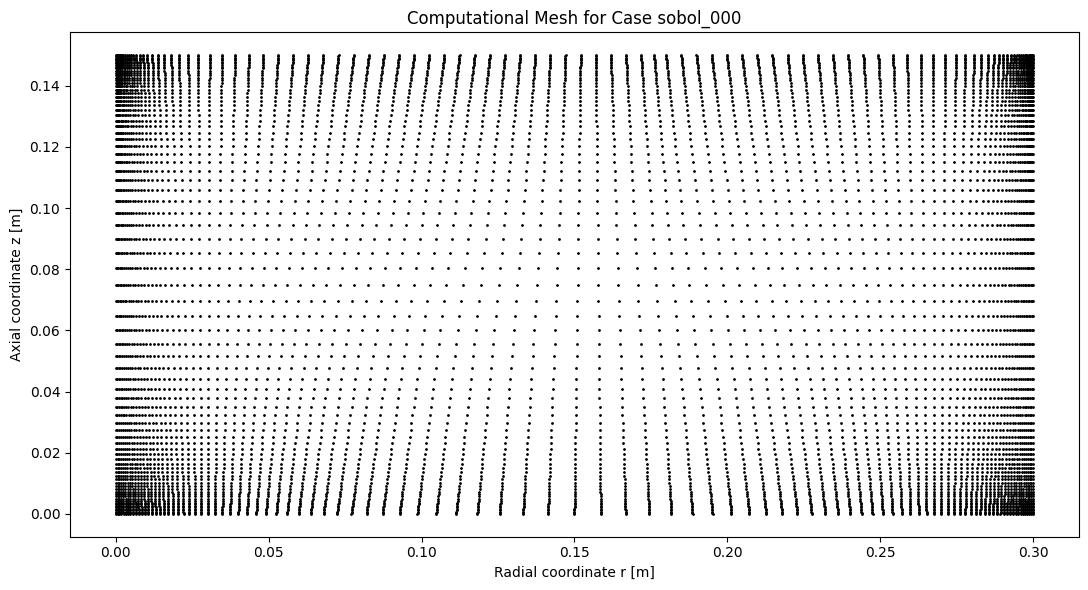

In [15]:
# Plots the meshes and nodes

fig, ax = plt.subplots(figsize=(12, 6))

ax.scatter(df["r"], df["z"], s=1, color="black")
ax.set_xlabel("Radial coordinate r [m]")
ax.set_ylabel("Axial coordinate z [m]")
ax.set_title(f"Computational Mesh for Case {case_id}")
ax.set_aspect("equal")

plt.tight_layout()
plt.show()

In [16]:
 # Investigate the mesh arrangement

print("Total nodes:",  len(df))
print("Uniques radial coordinates:", df["r"].nunique())
print("Uniques axial coordinates:", df["z"].nunique())  

nodes_per_level = df.groupby("z").size()

print("\nNodes per axial level:")
print(nodes_per_level.value_counts())

Total nodes: 8181
Uniques radial coordinates: 8021
Uniques axial coordinates: 81

Nodes per axial level:
101    81
Name: count, dtype: int64


In [17]:
# Create the logical grid

df_grid = df.sort_values(
    ["z", "r"]
).reset_index(drop=True)

nz = df["z"].nunique()
nr = int(nodes_per_level.iloc[0])

assert (nodes_per_level == nr).all()
assert nr * nz == len(df)

R = df_grid["r"].to_numpy().reshape(nz, nr)
Z = df_grid["z"].to_numpy().reshape(nz, nr)

print("R shape:", R.shape)
print("Z shape:", Z.shape)

R shape: (81, 101)
Z shape: (81, 101)


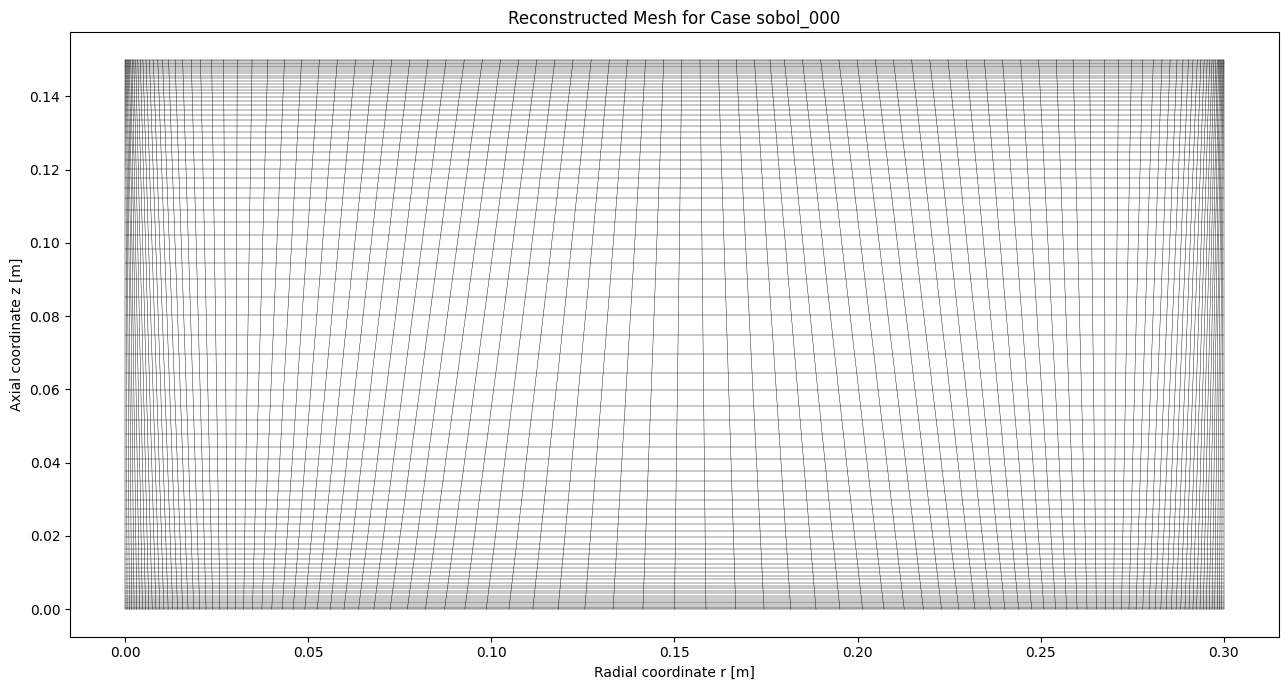

In [18]:
# visualize the reconstructed mesh

fig, ax = plt.subplots(figsize=(14, 7))

# Connect nodes along the radial direction
ax.plot(R.T, Z.T, color="black", linewidth=0.3)

# Connect nodes along the axial direction
ax.plot(R, Z, color="black", linewidth=0.3)

ax.set_xlabel("Radial coordinate r [m]")
ax.set_ylabel("Axial coordinate z [m]")
ax.set_title(f"Reconstructed Mesh for Case {case_id}")
ax.set_aspect("equal")

plt.tight_layout()
plt.show()

In [19]:
# Calculate mesh spacing

dr = np.diff(R, axis=1)
dz = np.diff(Z, axis=0)

print("minimum dr:", dr.min() )
print("maximum dr:", dr.max() )

print("minimum dz:", dz.min() )
print("maximum dz:", dz.max() )

minimum dr: 0.00016470819999997444
maximum dr: 0.008608049199999995
minimum dz: 0.0003576502000000037
maximum dz: 0.0053647536200000095


In [20]:
# Create physical field arrays

U_r = df_grid["u_r"].to_numpy().reshape(nz, nr)
U_z = df_grid["u_z"].to_numpy().reshape(nz, nr)
U_theta = df_grid["u_swirl"].to_numpy().reshape(nz, nr)
P = df_grid["p"].to_numpy().reshape(nz, nr)
T = df_grid["T"].to_numpy().reshape(nz, nr)

print(U_r.shape)
print(T.shape)

(81, 101)
(81, 101)


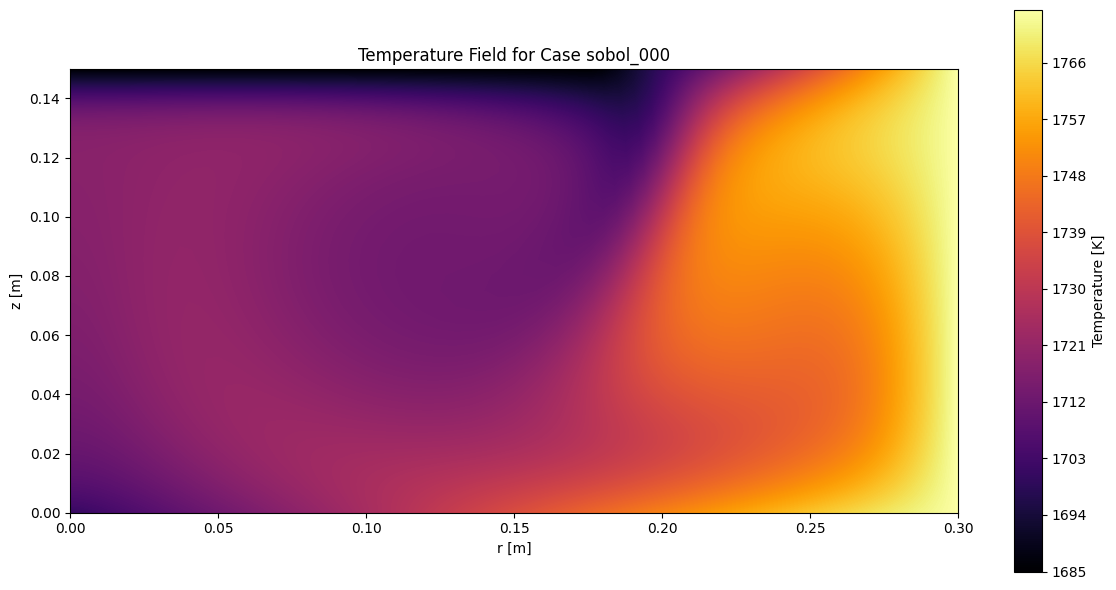

In [21]:
# tempeature field visualization

fig, ax = plt.subplots(figsize=(12, 6))

contour = ax.contourf(
    R, Z, T, levels=1000, cmap="inferno"
)

fig.colorbar(contour, ax=ax, label="Temperature [K]")

ax.set_xlabel("r [m]")
ax.set_ylabel("z [m]")
ax.set_title(f"Temperature Field for Case {case_id}")
ax.set_aspect("equal")

plt.tight_layout()
plt.show()

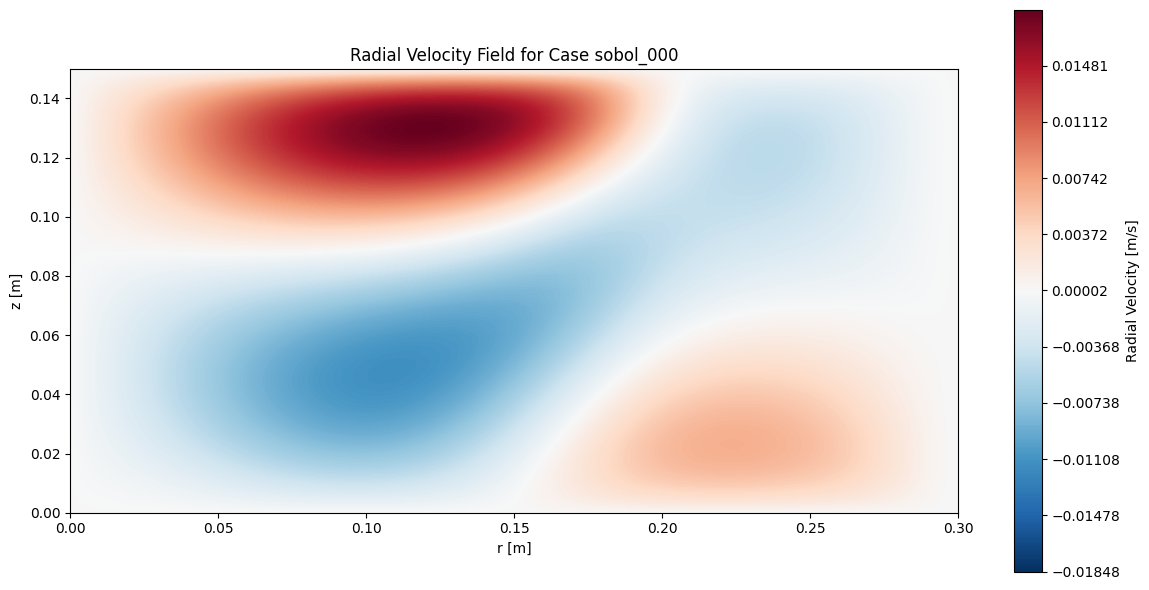

In [22]:
# Radial Velocity Field Visualization

fig, ax = plt.subplots(figsize=(12, 6))

vmax = np.abs(U_r).max()

contour = ax.contourf(
    R, Z, U_r, levels=np.linspace(-vmax, vmax, 1000), cmap="RdBu_r"
)

fig.colorbar(contour, ax=ax, label="Radial Velocity [m/s]")

ax.set_xlabel("r [m]")
ax.set_ylabel("z [m]")
ax.set_title(f"Radial Velocity Field for Case {case_id}")
ax.set_aspect("equal")

plt.tight_layout()
plt.show()



In [23]:
# Generic scalar field visualization function

def plot_field(field,
               title,
               unit,
               cmap="RdBu_r",
               symmetric=False):

    fig, ax = plt.subplots(figsize=(12, 6))

    if symmetric:
        vmax = np.abs(field).max()
        levels = np.linspace(-vmax, vmax, 51)
    else:
        levels = 50

    contour = ax.contourf(
        R, Z, field, levels=levels, cmap=cmap
    )

    fig.colorbar(contour, ax=ax, label=unit)

    ax.set_xlabel("r [m]")
    ax.set_ylabel("z [m]")
    ax.set_title(title)
    ax.set_aspect("equal")

    plt.tight_layout()
    plt.show()


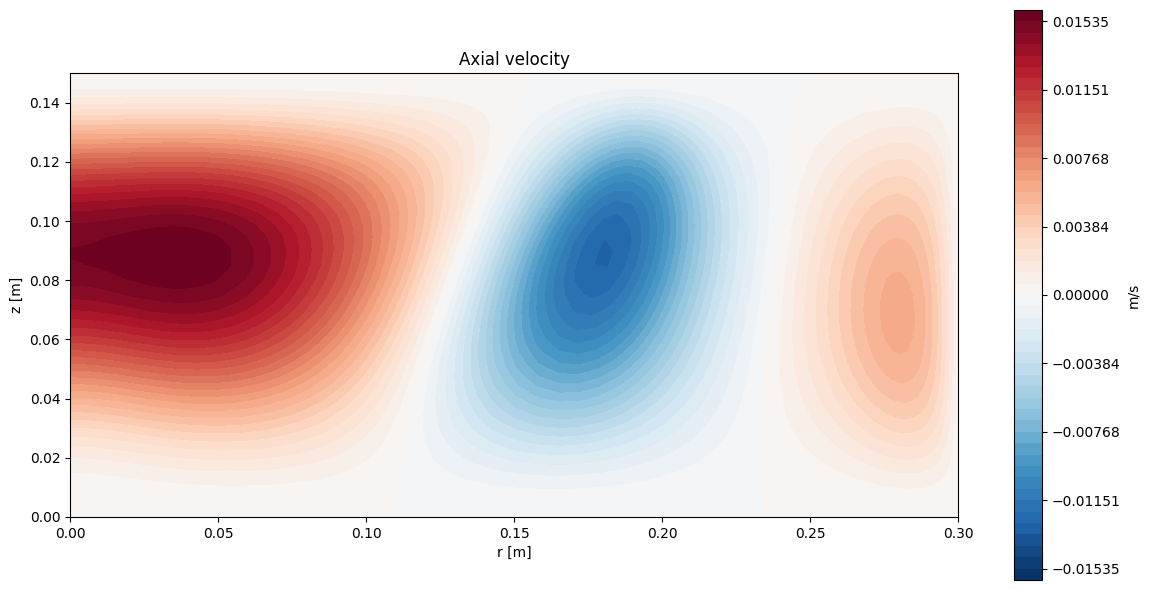

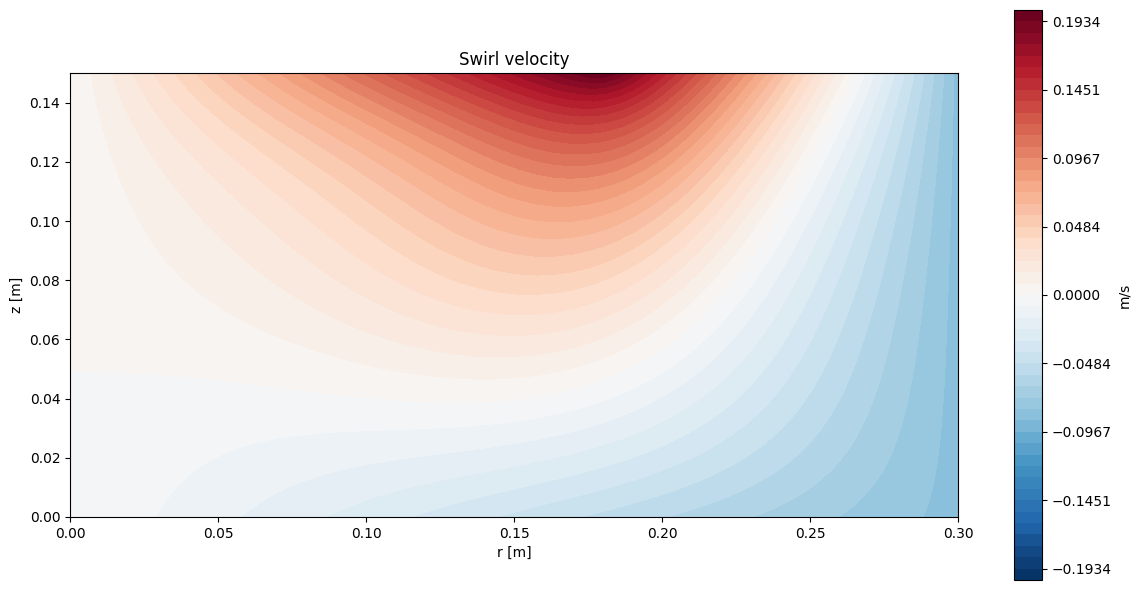

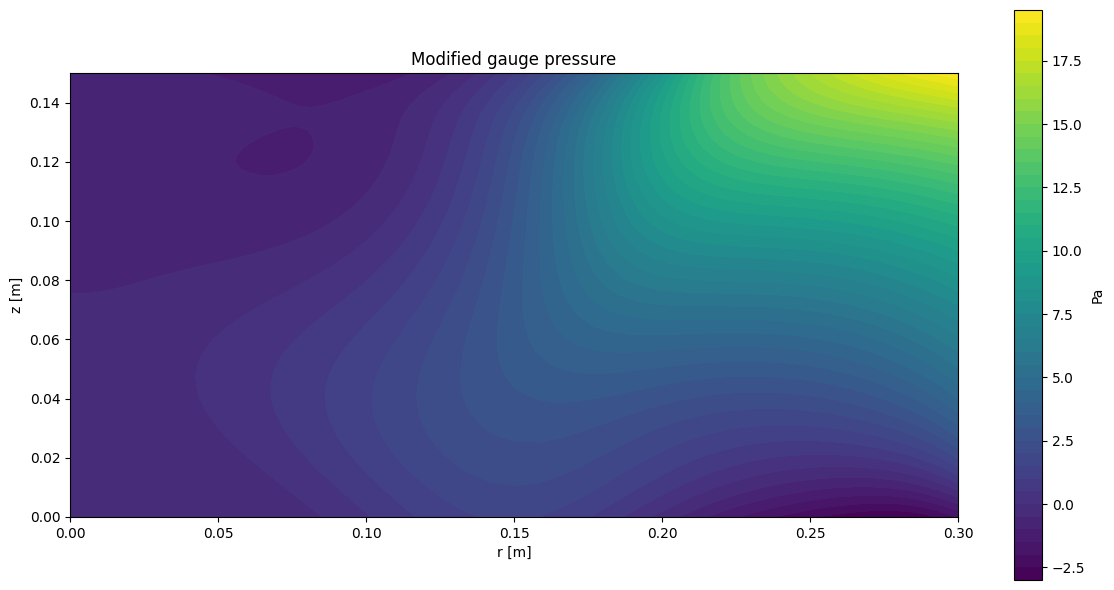

In [24]:
plot_field(
    U_z,
    "Axial velocity",
    "m/s",
    symmetric=True
)

plot_field(
    U_theta,
    "Swirl velocity",
    "m/s",
    symmetric=True
)

plot_field(
    P,
    "Modified gauge pressure",
    "Pa",
    cmap="viridis"
)

In [25]:
# Calculate velocity magnitudes

U_meriodinal = np.sqrt(U_r**2 + U_z**2)

U_total = np.sqrt(U_r**2 + U_z**2 + U_theta**2)

print("Maximum meridional velocity:", U_meriodinal.max())
print("Maximum total velocity:", U_total.max())

Maximum meridional velocity: 0.018631285221802747
Maximum total velocity: 0.2014794657


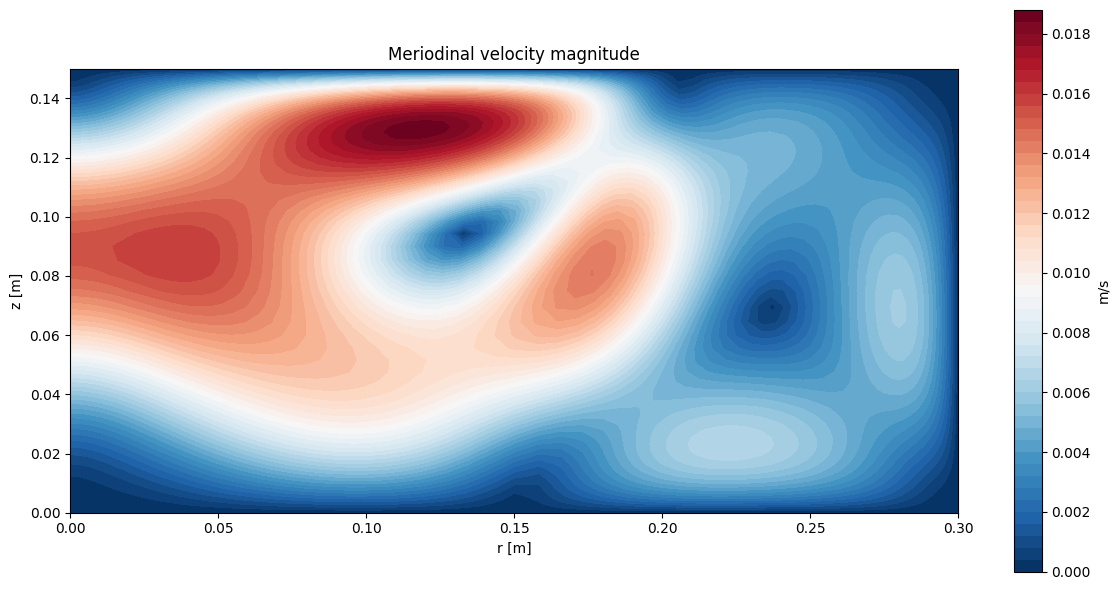

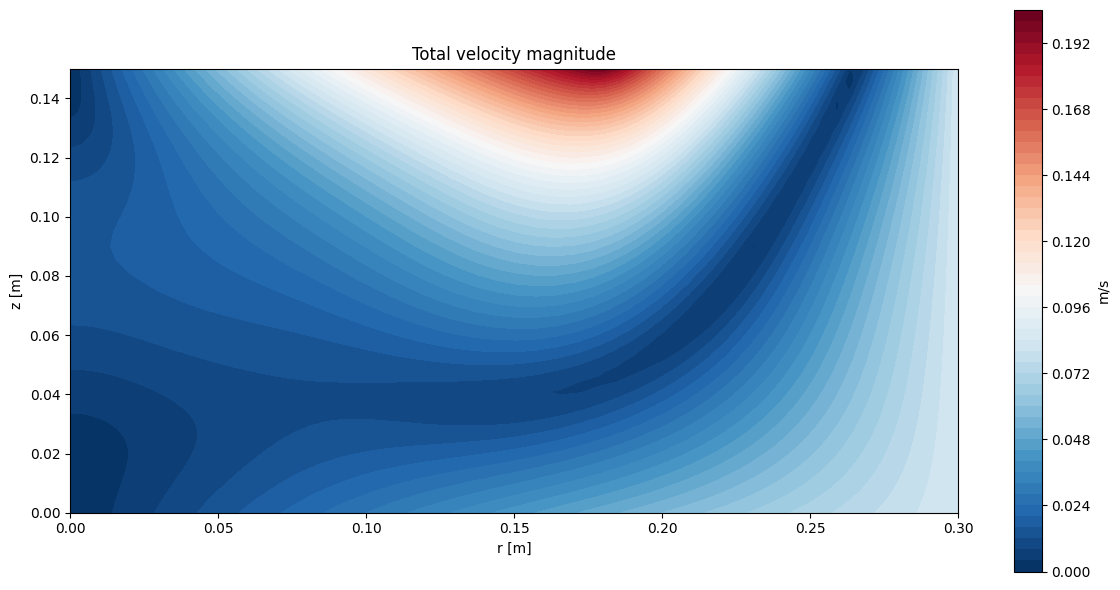

In [26]:
# Visualize velocity magnitudes

plot_field(
    U_meriodinal,
    "Meriodinal velocity magnitude",
    "m/s",
   # cmap="viridis"
)

plot_field(
    U_total,
    "Total velocity magnitude",
    "m/s",
    #cmap="viridis"
)

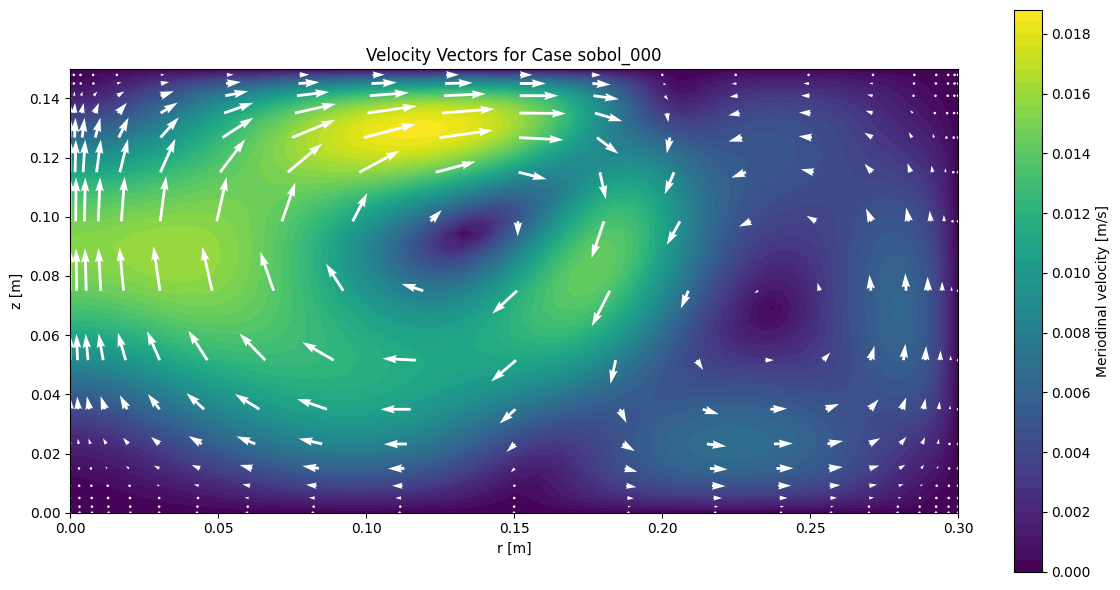

In [27]:
# Velocity vectors visualization

fig, ax = plt.subplots(figsize=(12, 6)) 

contour = ax.contourf(
    R, Z, U_meriodinal, levels=50, cmap="viridis"
)

step = 5

ax.quiver(
    R[::step, ::step],
    Z[::step, ::step],
    U_r[::step, ::step],
    U_z[::step, ::step],
    color="white",
    angles="xy",
    scale_units="xy",
    scale=1.0
)

fig.colorbar(
    contour, ax=ax, label="Meriodinal velocity [m/s]"
)

ax.set_xlabel("r [m]")
ax.set_ylabel("z [m]")
ax.set_title(f"Velocity Vectors for Case {case_id}")    
ax.set_aspect("equal")

plt.tight_layout()
plt.show()

## Visulize melt ciculation with streamlinnes

In [28]:
# Interpolate on the uniform grid

from scipy.interpolate import griddata

r_uniform = np.linspace(
    df["r"].min(),
    df["r"].max(),
    220
)

z_uniform = np.linspace(
    df["z"].min(),
    df["z"].max(),
    110
)

R_uniform, Z_uniform = np.meshgrid(
    r_uniform,
    z_uniform
)

U_r_uniform = griddata(
    pos,
    df["u_r"].to_numpy(),
    (R_uniform, Z_uniform),
    method="linear"
)

U_z_uniform = griddata(
    pos,
    df["u_z"].to_numpy(),
    (R_uniform, Z_uniform),
    method="linear"
)

speed_uniform = np.hypot(
    U_r_uniform,
    U_z_uniform
)

print("Shape:", U_r_uniform.shape)
print("Missing values:", np.isnan(U_r_uniform).sum())



Shape: (110, 220)
Missing values: 0


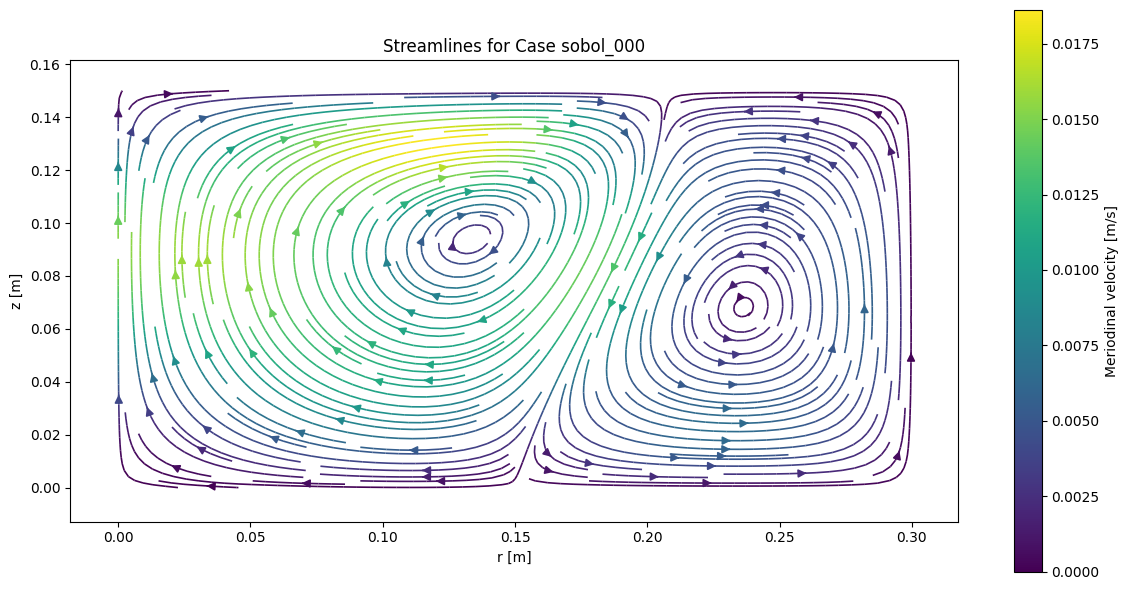

In [29]:
# PLot the streamlines

fig, ax = plt.subplots(figsize=(12, 6))

stream = ax.streamplot(
    R_uniform,
    Z_uniform,
    U_r_uniform,
    U_z_uniform,
    color=speed_uniform,
    cmap="viridis",
    density=2.0,
    linewidth=1.2,
    arrowsize=1.2
)

fig.colorbar(stream.lines, ax=ax, label="Meriodinal velocity [m/s]")
ax.set_xlabel("r [m]")
ax.set_ylabel("z [m]")
ax.set_title(f"Streamlines for Case {case_id}")
ax.set_aspect("equal")

plt.tight_layout()
plt.show()

## Combine Temperature and velocity contours

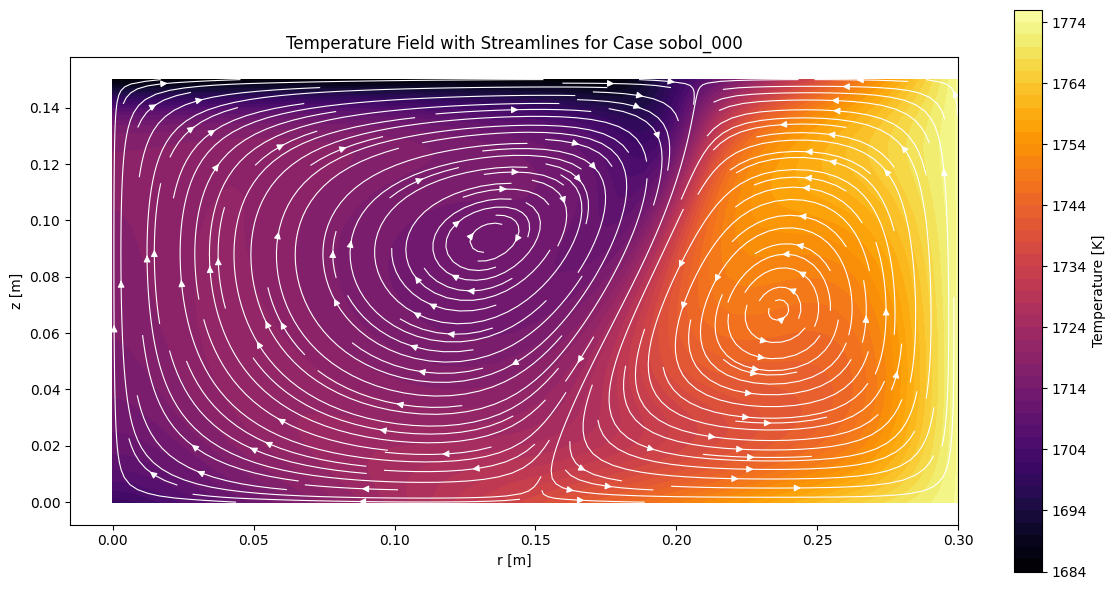

In [30]:
fig, ax = plt.subplots(figsize=(12, 6))

contour = ax.contourf(
    R, Z, T,
    levels=50,
    cmap="inferno"
)
ax.streamplot(
    r_uniform,
    z_uniform,
    U_r_uniform,
    U_z_uniform,
    color="white",
    density=1.8,
    linewidth=0.8,
    arrowsize=1.0
)

fig.colorbar(contour, ax=ax, label="Temperature [K]")

ax.set_xlabel("r [m]")
ax.set_ylabel("z [m]")
ax.set_title(f"Temperature Field with Streamlines for Case {case_id}")
ax.set_aspect("equal")

plt.tight_layout()
plt.show()

## Complete CFD Visualization

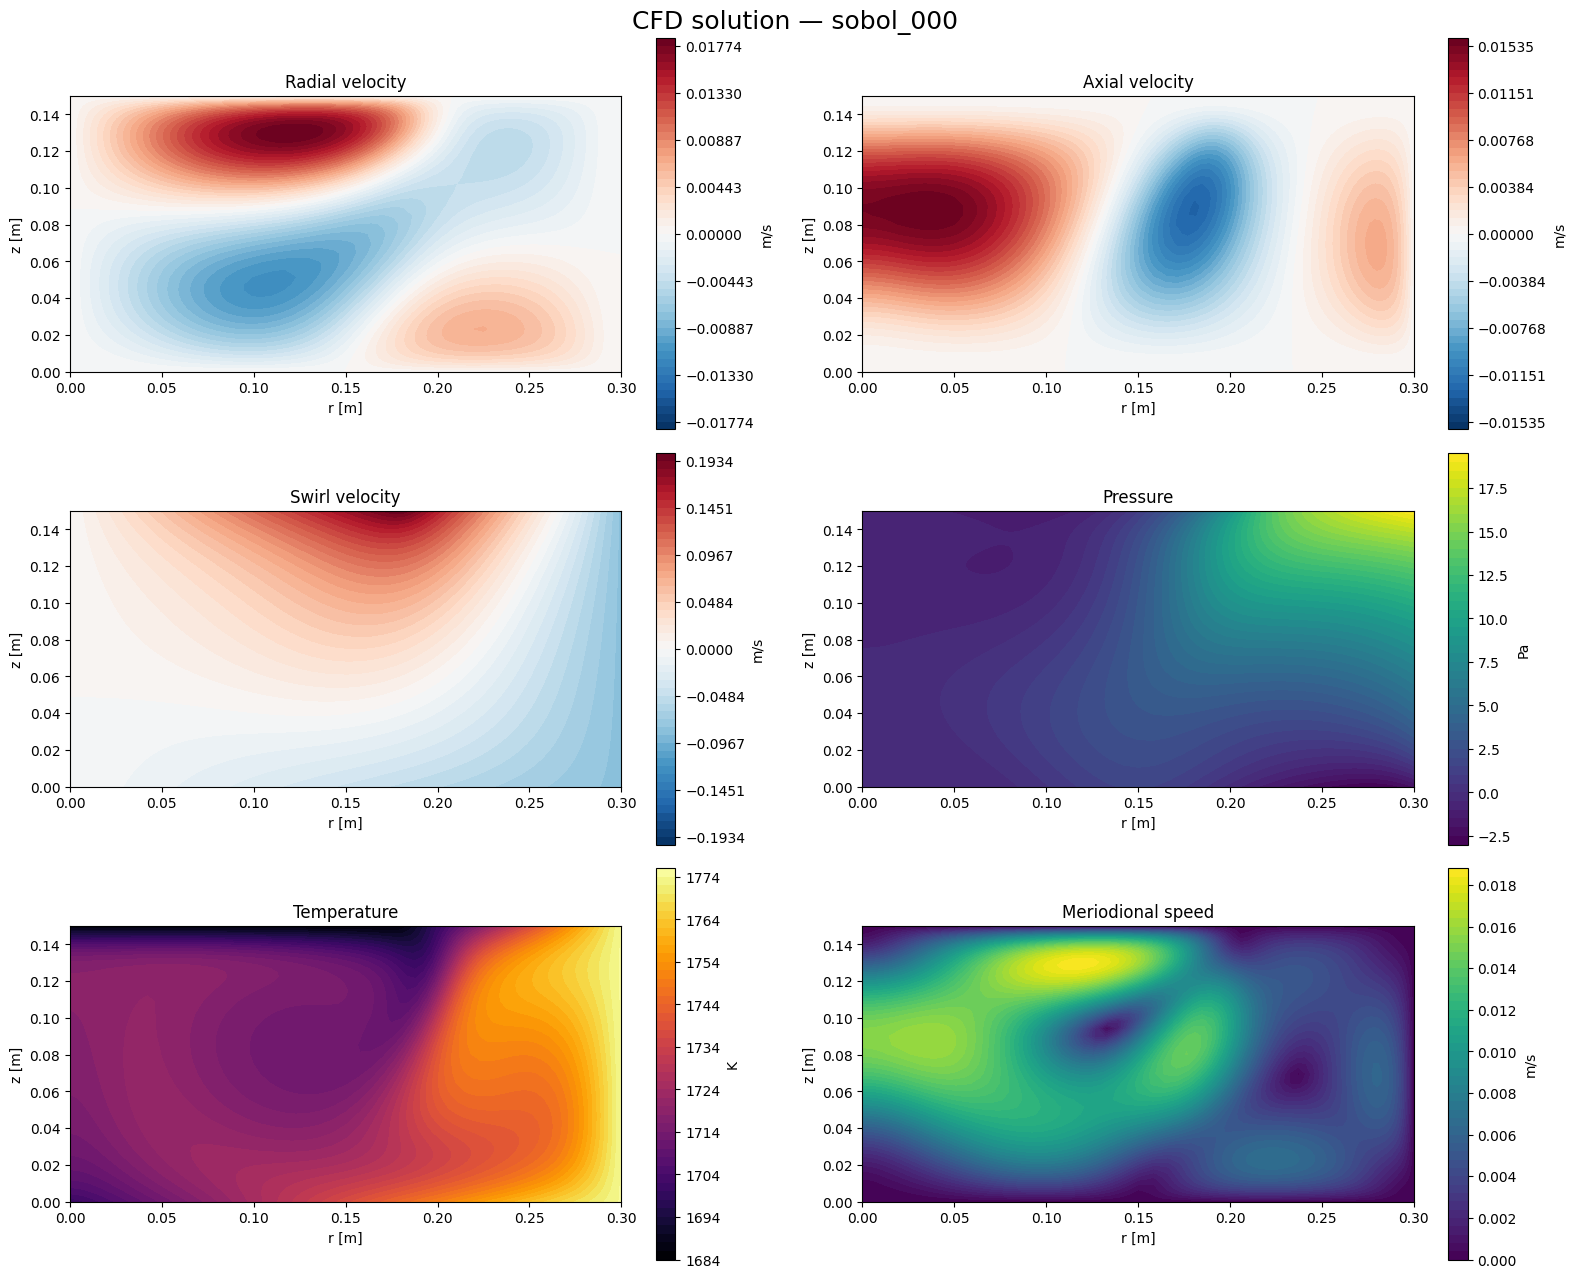

In [31]:
# Multi-field visualization

fields = [
    (U_r, "Radial velocity", "m/s", "RdBu_r", True),
    (U_z, "Axial velocity", "m/s", "RdBu_r", True),
    (U_theta, "Swirl velocity", "m/s", "RdBu_r", True),
    (P, "Pressure", "Pa", "viridis", False),
    (T, "Temperature", "K", "inferno", False),
    (U_meriodinal, "Meriodional speed", "m/s", "viridis", False)
]

fig, axes = plt.subplots(3, 2, figsize=(16, 13))

for ax, (field, title, unit, cmap, symmetric) in zip(
    axes.flat, fields
):

    if symmetric:
        vmax = np.abs(field).max()
        levels = np.linspace(-vmax, vmax, 51)
    else:
        levels = 50

    contour = ax.contourf(
        R, Z, field,
        levels=levels,
        cmap=cmap
    )

    fig.colorbar(contour, ax=ax, label=unit)

    ax.set_title(title)
    ax.set_xlabel("r [m]")
    ax.set_ylabel("z [m]")
    ax.set_aspect("equal")

fig.suptitle(f"CFD solution — {case_id}", fontsize=18)

plt.tight_layout()
plt.savefig(f"../figures/{case_id}_multi_field.png", dpi=300)
plt.show()

## Visualize the DOE parameter list

In [32]:
# Prepare case metadata

parameter_columns = [
    "crystal_rpm",
    "crucible_rpm",
    "t_hot"
]

metadata = cases.merge(
    status[["case_id", "status", "iterations"]],
    on="case_id",
    how="left",
    validate="one_to_one"
)

kept = metadata[metadata["status"] == "kept"].copy()
excluded = metadata[metadata["status"] == "excluded"].copy()

print("Total cases:", len(metadata))
print("Kept cases:", len(kept))
print("Excluded cases:", len(excluded))

Total cases: 265
Kept cases: 254
Excluded cases: 11


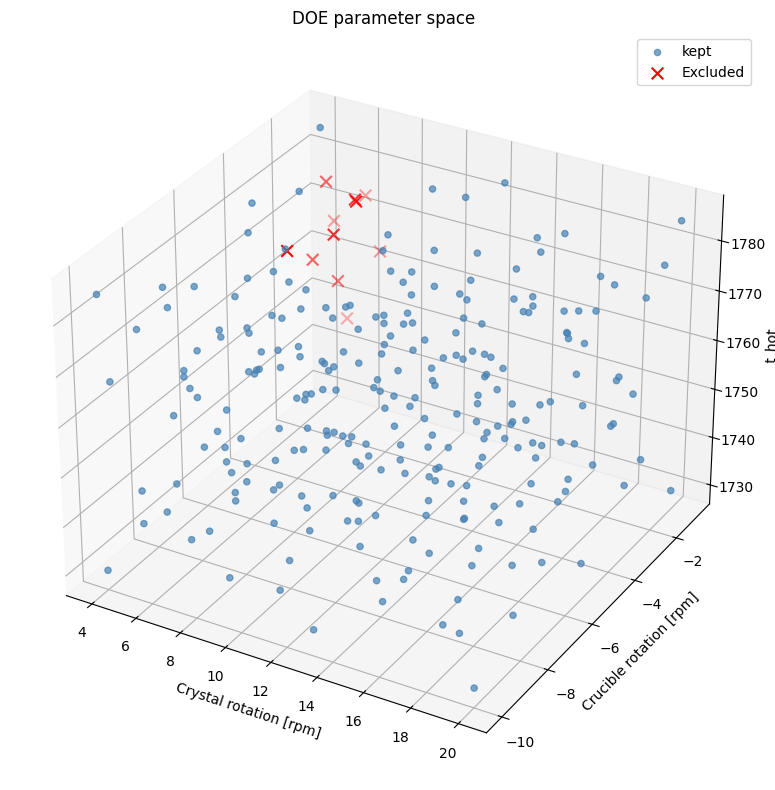

In [33]:
# Visualize the 3D parameter sapce

fig = plt.figure(figsize=(11, 8))
ax = fig.add_subplot(111, projection="3d")

ax.scatter(
    kept["crystal_rpm"],
    kept["crucible_rpm"],
    kept["t_hot"],
    c="steelblue",
    s=20,
    alpha=0.7,
    label="kept"
)

ax.scatter(
    excluded["crystal_rpm"],
    excluded["crucible_rpm"],
    excluded["t_hot"],
    c="red",
    marker='x',
    s=70,
    label="Excluded"
)

ax.set_xlabel("Crystal rotation [rpm]")
ax.set_ylabel("Crucible rotation [rpm]")
ax.set_zlabel("t_hot")

ax.set_title("DOE parameter space")
ax.legend()

plt.tight_layout()
plt.show()

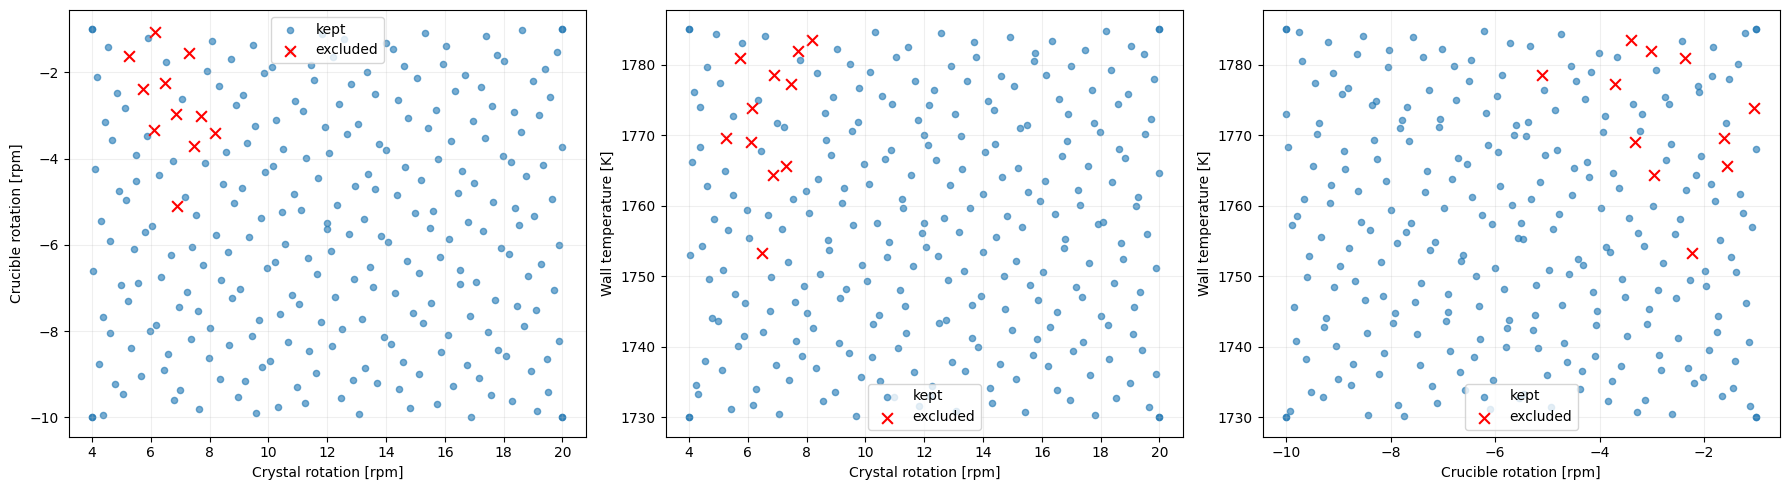

In [34]:
# Pairwise paramter-space coverage

pairs = [
    ("crystal_rpm", "crucible_rpm"),
    ("crystal_rpm", "t_hot"),
    ("crucible_rpm", "t_hot")
]

labels = {
    "crystal_rpm": "Crystal rotation [rpm]",
    "crucible_rpm": "Crucible rotation [rpm]",
    "t_hot": "Wall temperature [K]" 
}

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, (xcol, ycol) in zip(axes, pairs):
    ax.scatter(
        kept[xcol],
        kept[ycol],
        s=20,
        alpha=0.6,
        label="kept"
    )

    ax.scatter(
        excluded[xcol],
        excluded[ycol],
        s=60,
        marker='x',
        color='red',
        label="excluded"
    )

    ax.set_xlabel(labels[xcol])
    ax.set_ylabel(labels[ycol])
    ax.grid(alpha=0.2)
    ax.legend()

plt.tight_layout()
plt.show()


## Simulationn Loader

In [35]:
## Reusable Simulation loading funnction

def load_case(case_name):

    with zipfile.ZipFile(DOE_ZIP, "r") as archive:

        with archive.open(
            f"doe/{case_name}.csv"
        ) as file:
            data = pd.read_csv(file)

    info = metadata.set_index("case_id").loc[case_name]

    return data, info


In [36]:
data, info = load_case("corner_000")

print(data.shape)
print(info[parameter_columns])

(8181, 7)
crystal_rpm        4.0
crucible_rpm     -10.0
t_hot           1730.0
Name: corner_000, dtype: object


In [37]:
# Convert a case into a logical mesh

def get_case_grid(case_name):

    data, info = load_case(case_name)

    data = data.sort_values(
        ["z", "r"]
    ).reset_index(drop=True)

    nr = int(data.groupby("z").size().iloc[0])
    nz = data["z"].nunique()

    assert nr * nz == len(data)
    assert (data.groupby("z").size() == nr).all()

    grid = {}

    for col in data.columns:
        grid[col] = data[col].to_numpy().reshape(nr, nz)

    grid["U_meriodinal"] = np.hypot(
        grid["u_r"],
        grid["u_z"]
    )

    grid["U_total"] = np.sqrt(
        grid["u_r"]**2 +
        grid["u_z"]**2 +
        grid["u_swirl"]**2
    )

    return grid, info

## Comparative plotting funciton over cases

In [38]:
# compare a physical field across different cases

def compare_cases(case_names,
                  field,
                  cmap="veridis",
                  symmetric=False):

    results = [
        get_case_grid(name) for name in case_names
    ]

    vmin = min(grid[field].min() for grid, info in results)

    vmax = max(grid[field].max() for grid, info in results)

    if symmetric:
        limit = max(abs(vmin), abs(vmax))
        vmin, vmax = -limit, limit 

    levels = np.linspace(vmin, vmax, 51)

    n = len(case_names)

    fig, axes = plt.subplots(
        1, n,
        figsize=(7 * n, 5),
        constrained_layout=True
    )

    axes = np.atleast_1d(axes)

    for ax, name, (grid, info) in zip(
        axes, case_names, results
    ):
        contour = ax.contourf(
            grid["r"],
            grid["z"],
            grid[field],
            levels=levels,
            cmap=cmap

        )
        ax.set_title(
            f"{name}\n"
            f"Crystal = {info["crystal_rpm"]:.1f} rpm\n"
            f"Crusible = {info["crucible_rpm"]:.1f} rpm\n"
            f"T_hot = {info["t_hot"]:.1f} K"
        )

        ax.set_xlabel("r [m]")
        ax.set_ylabel("z [m]")
        ax.set_aspect("equal")

    units = {
        "T": "K",
        "p": "Pa",
        "u_r": "m/s",
        "u_z": "m/s",
        "u_swirl": "m/s",
        "U_meriodinal": "m/s",
        "U_total": "m/s"
    }

    fig.colorbar(
        contour,
        ax=axes.tolist(),
        label=f"{field} [{units[field]}]",
        shrink=0.8
    )

    plt.show()

### Compare low and high crystal rotation

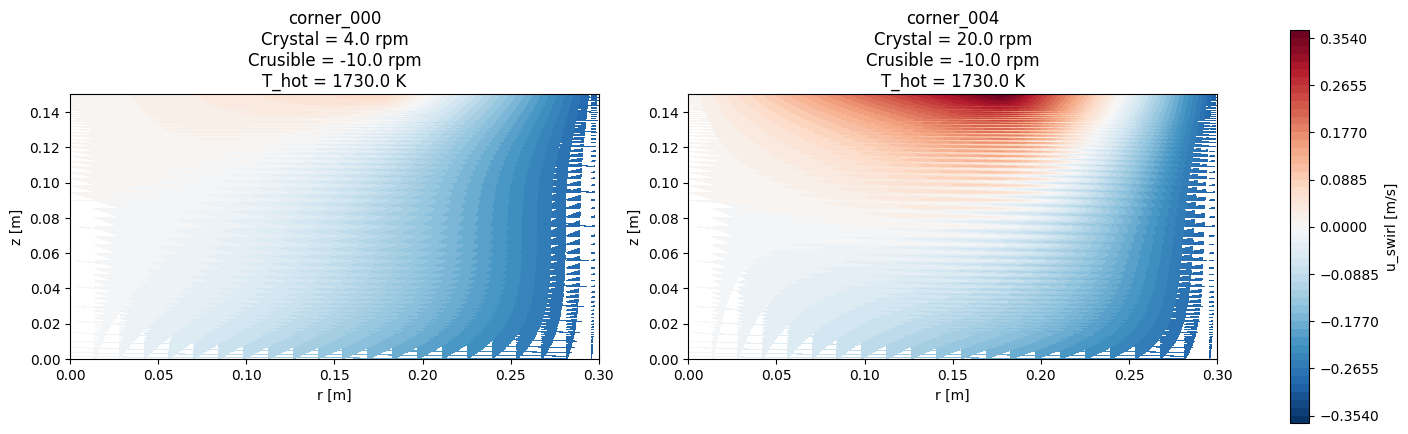

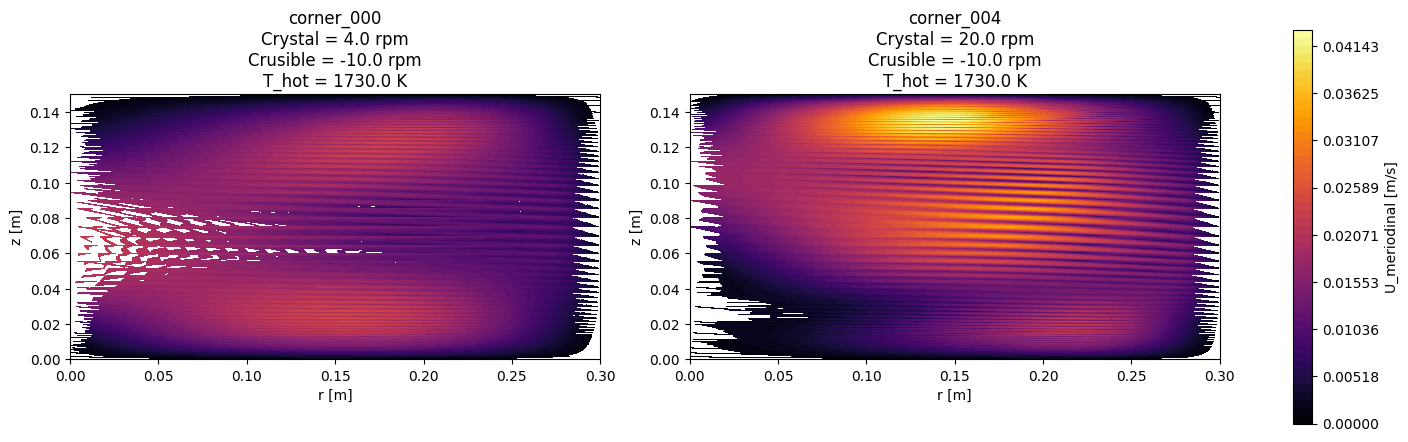

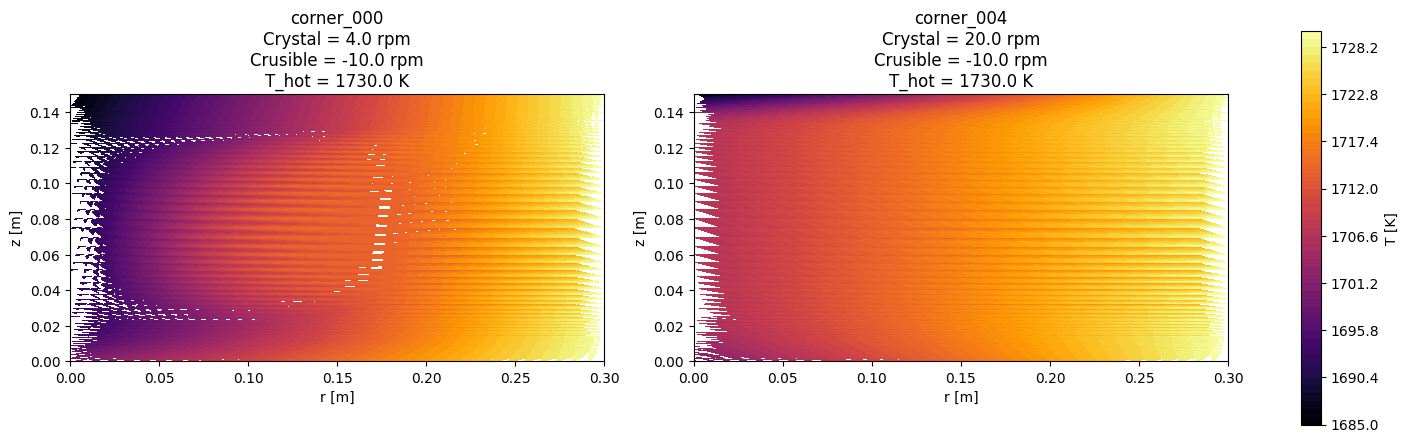

In [39]:
crystal_cases = [
    "corner_000",
    "corner_004"
]

compare_cases(
    crystal_cases,
    "u_swirl",
    cmap="RdBu_r",
    symmetric=True
)

compare_cases(
    crystal_cases,
    "U_meriodinal",
    cmap="inferno"
)

compare_cases(
    crystal_cases,
    "T",
    cmap="inferno"
)

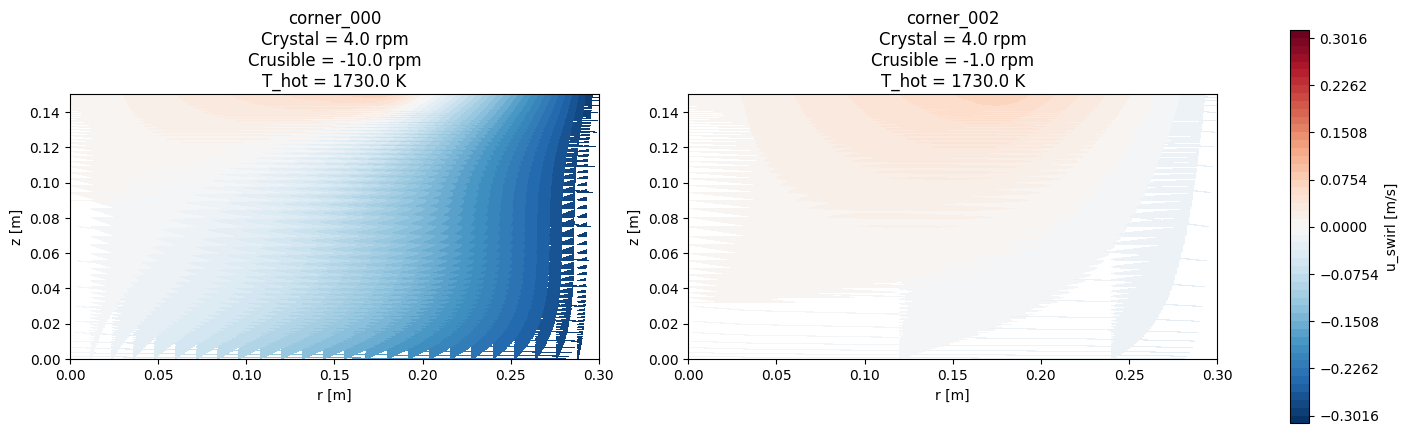

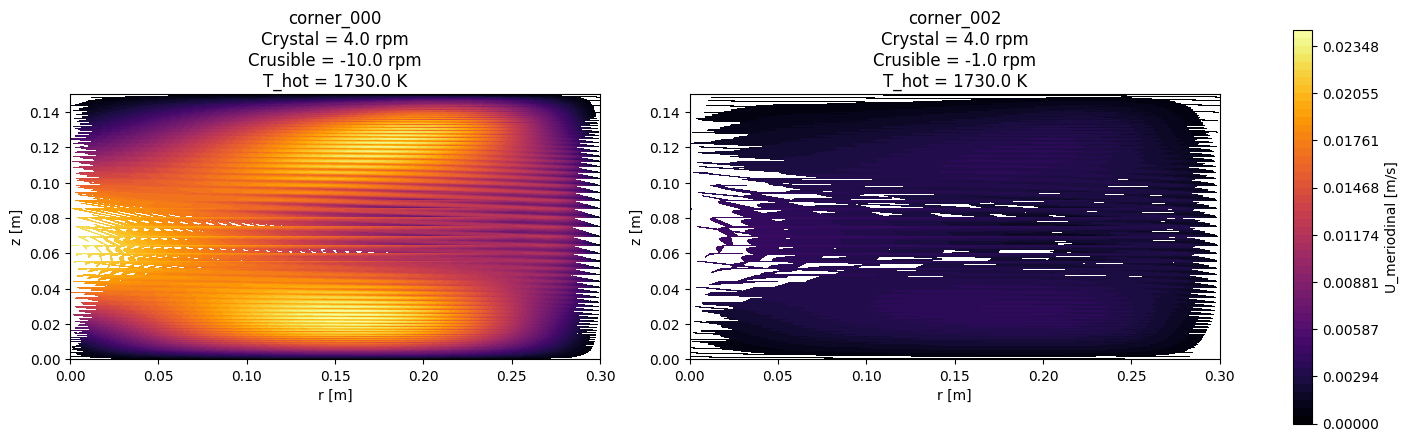

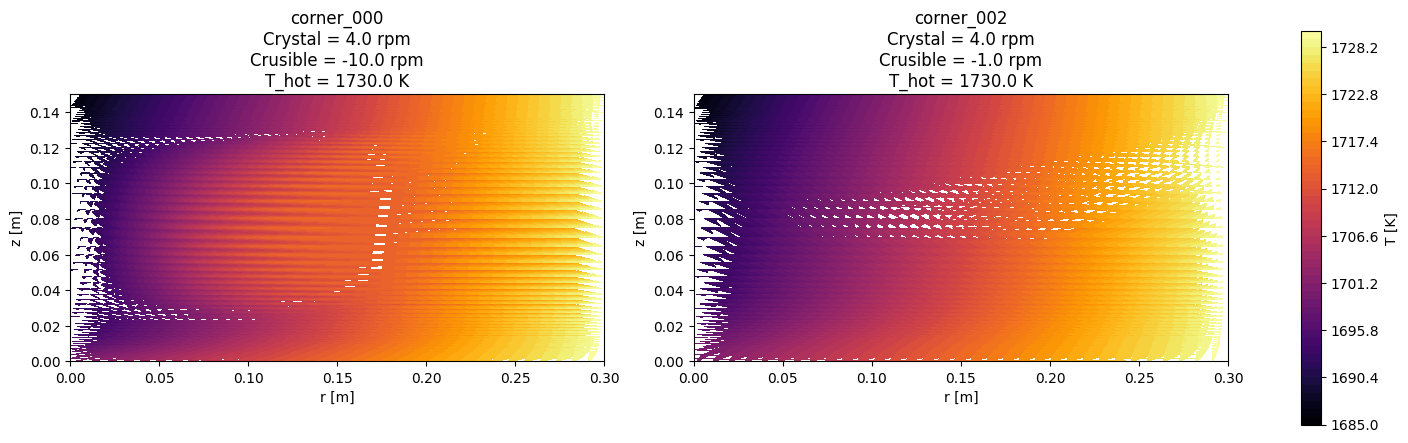

In [40]:
# Effect of crucible rotation

crucible_cases = [
    "corner_000",
    "corner_002"
]

compare_cases(
    crucible_cases,
    "u_swirl",
    cmap="RdBu_r",
    symmetric=True
)

compare_cases(
    crucible_cases,
    "U_meriodinal",
    cmap="inferno"
)

compare_cases(
    crucible_cases,
    "T",
    cmap="inferno"
)

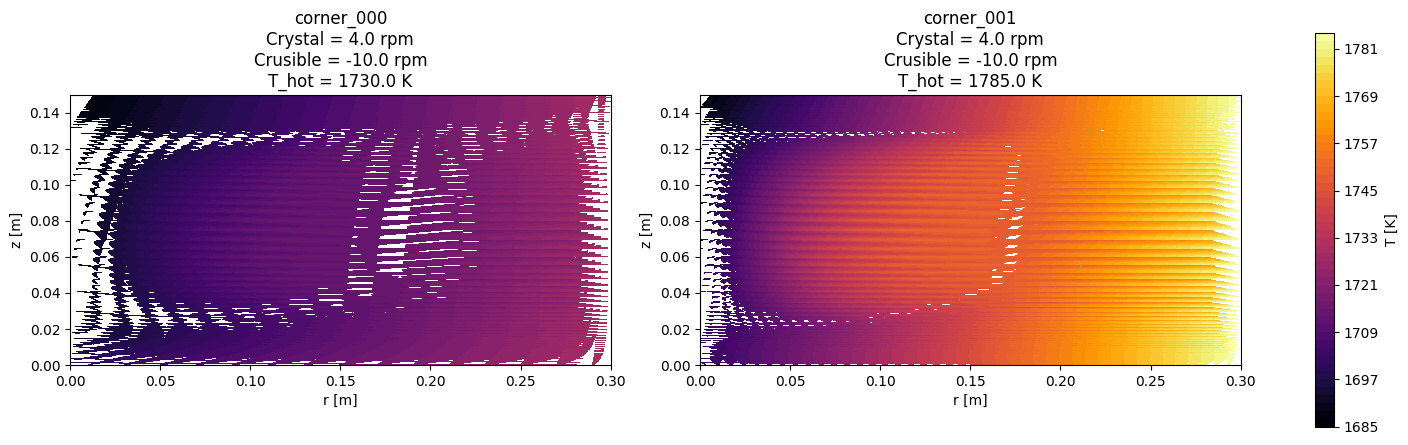

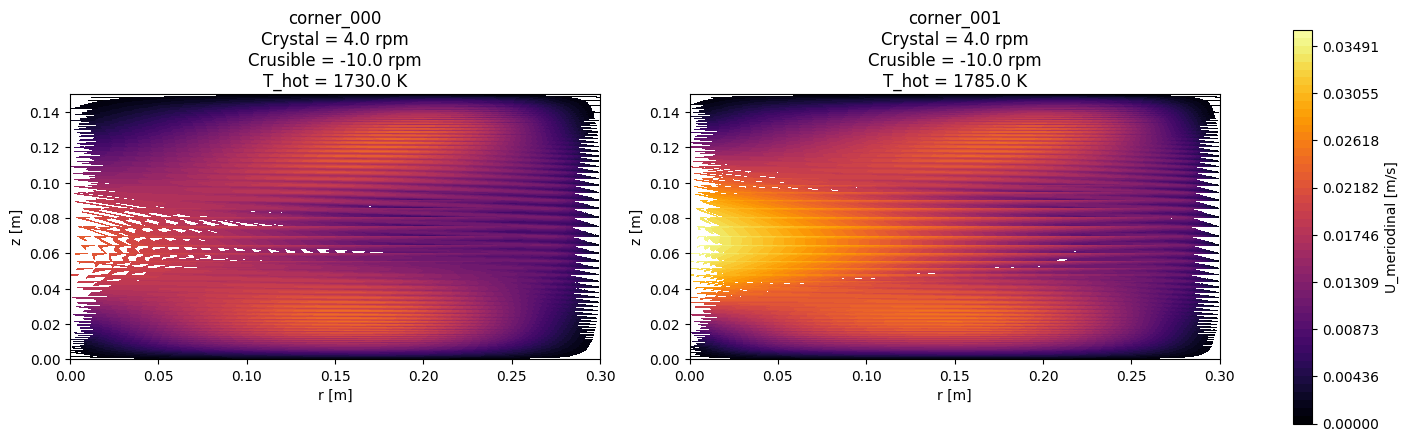

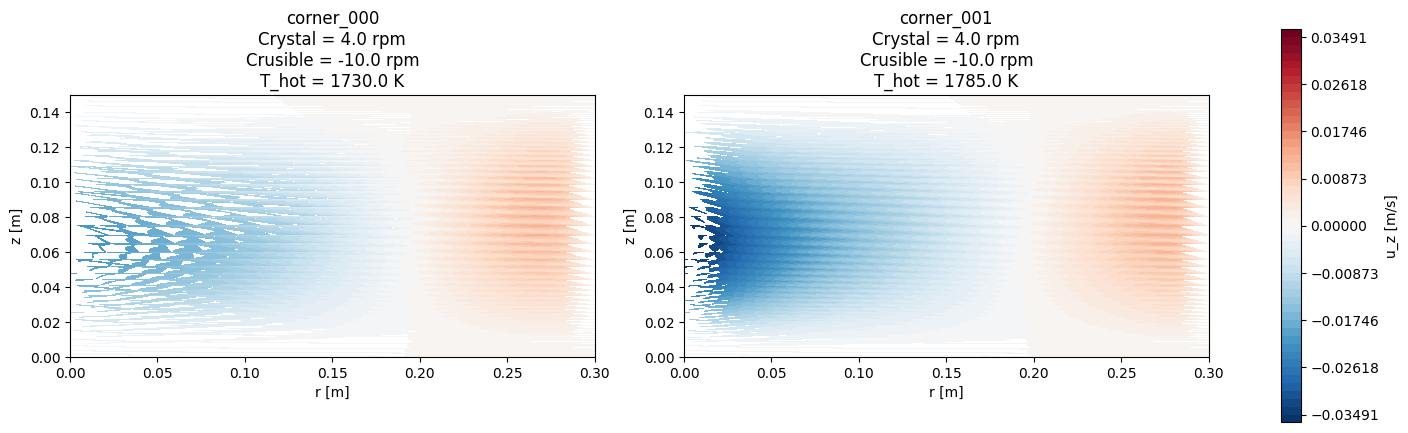

In [41]:
# Effect of Wall Temperature

temperature_cases = [
    "corner_000",
    "corner_001"
]

compare_cases(
    temperature_cases,
    "T",
    cmap="inferno"
)

compare_cases(
    temperature_cases,
    "U_meriodinal",
    cmap="inferno"
)

compare_cases(
    temperature_cases,
    "u_z",
    cmap="RdBu_r",
    symmetric=True
)

# Parameter interactions

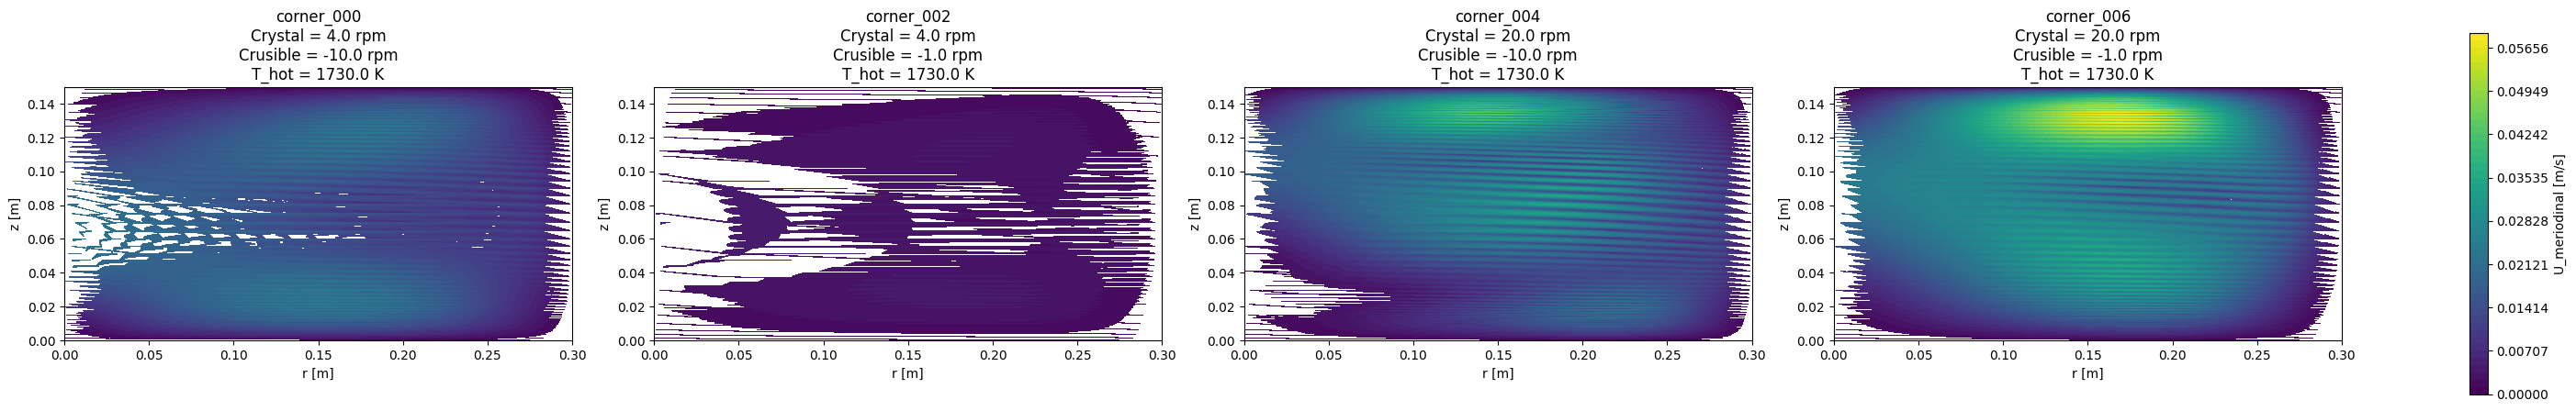

In [42]:
# Interaction between crystal and crucible rotation

interaction_cases = [
    "corner_000",
    "corner_002",
    "corner_004",
    "corner_006"
]

compare_cases(
    interaction_cases,
    "U_meriodinal",
    cmap="viridis"
)

## Calculate Quantities for one case

In [43]:
def calculate_quantities(data):

    u_meriodinal = np.hypot(
        data["u_r"],
        data["u_z"]
    )

    u_total = np.sqrt(
        data["u_r"]**2 +
        data["u_z"]**2 +
        data["u_swirl"]**2
    )

    return {
        "max_meriodinal": u_meriodinal.max(),
        "rms_meriodinal": np.sqrt(
            np.mean(u_meriodinal**2)
        ),
        "max_swirl": data["u_swirl"].abs().max(),
        "max_total": u_total.max(),
        "mean_T": data["T"].mean(),
        "min_T": data["T"].min(),
        "max_T": data["T"].max(),
        "delta_T": data["T"].max() - data["T"].min()
    }


In [44]:
# Calculate QoI for all DOE cases

records = []

for name in kept["case_id"]:
    data, info = load_case(name)

    quantities = calculate_quantities(data)

    record = {
        "case_id": name,
        **quantities
    }

    records.append(record)

qoi_df = pd.DataFrame(records)

qoi_df = kept.merge(
    qoi_df,
    on="case_id",
    validate="one_to_one"
)

print(qoi_df.shape)

qoi_df.head()

(254, 15)


,case_id,group,crystal_rpm,crucible_rpm,t_hot,status,iterations,max_meriodinal,rms_meriodinal,max_swirl,max_total,mean_T,min_T,max_T,delta_T
0,sobol_000,sobol,10.896472,-2.670688,1774.352702,kept,4155,0.018631,0.006505,0.201479,0.201479,1731.684882,1685.0,1774.352702,89.352702
1,sobol_001,sobol,17.917017,-6.062550,1757.430408,kept,3698,0.041552,0.011334,0.330808,0.330808,1724.318984,1685.0,1757.430408,72.430408
2,sobol_002,sobol,13.246647,-5.408550,1769.955855,kept,3195,0.023084,0.007567,0.244310,0.244310,1730.071373,1685.0,1769.955855,84.955855
3,sobol_003,sobol,6.189864,-7.851605,1731.750599,kept,3638,0.018871,0.007293,0.246665,0.246665,1708.960607,1685.0,1731.750599,46.750599
4,sobol_004,sobol,4.694309,-3.565196,1749.589687,kept,3115,0.013018,0.004341,0.112004,0.112004,1717.161136,1685.0,1749.589687,64.589687


## Visualize the distribution of physcial quantities

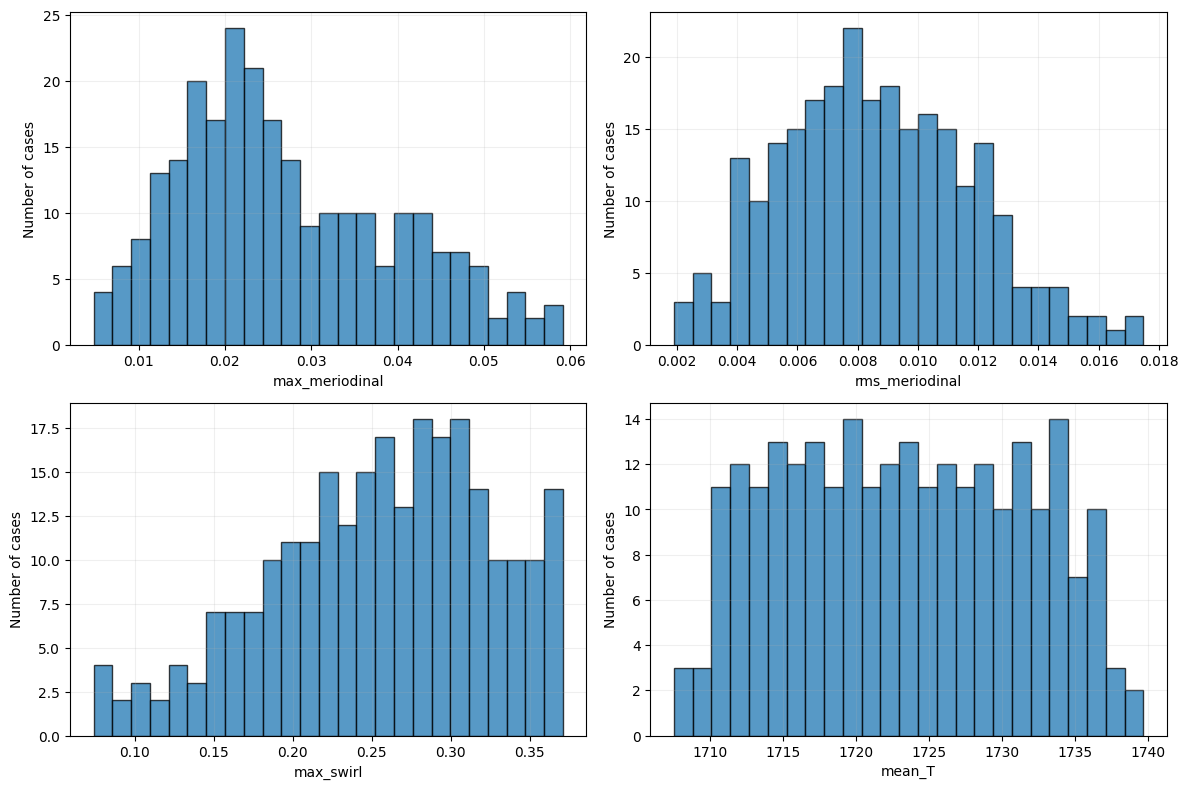

In [47]:
qoi_columns = [
    "max_meriodinal",
    "rms_meriodinal",
    "max_swirl",
    "mean_T"
]

fig, axes = plt.subplots(2, 2, figsize=(12,8))

for ax, col in zip(axes.flat, qoi_columns):
    ax.hist(
        qoi_df[col],
        bins=25,
        edgecolor="black",
        alpha=0.75
    )
    ax.set_xlabel(col)
    ax.set_ylabel("Number of cases")
    ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

## Analysis of realtionships between Inputs and outputs

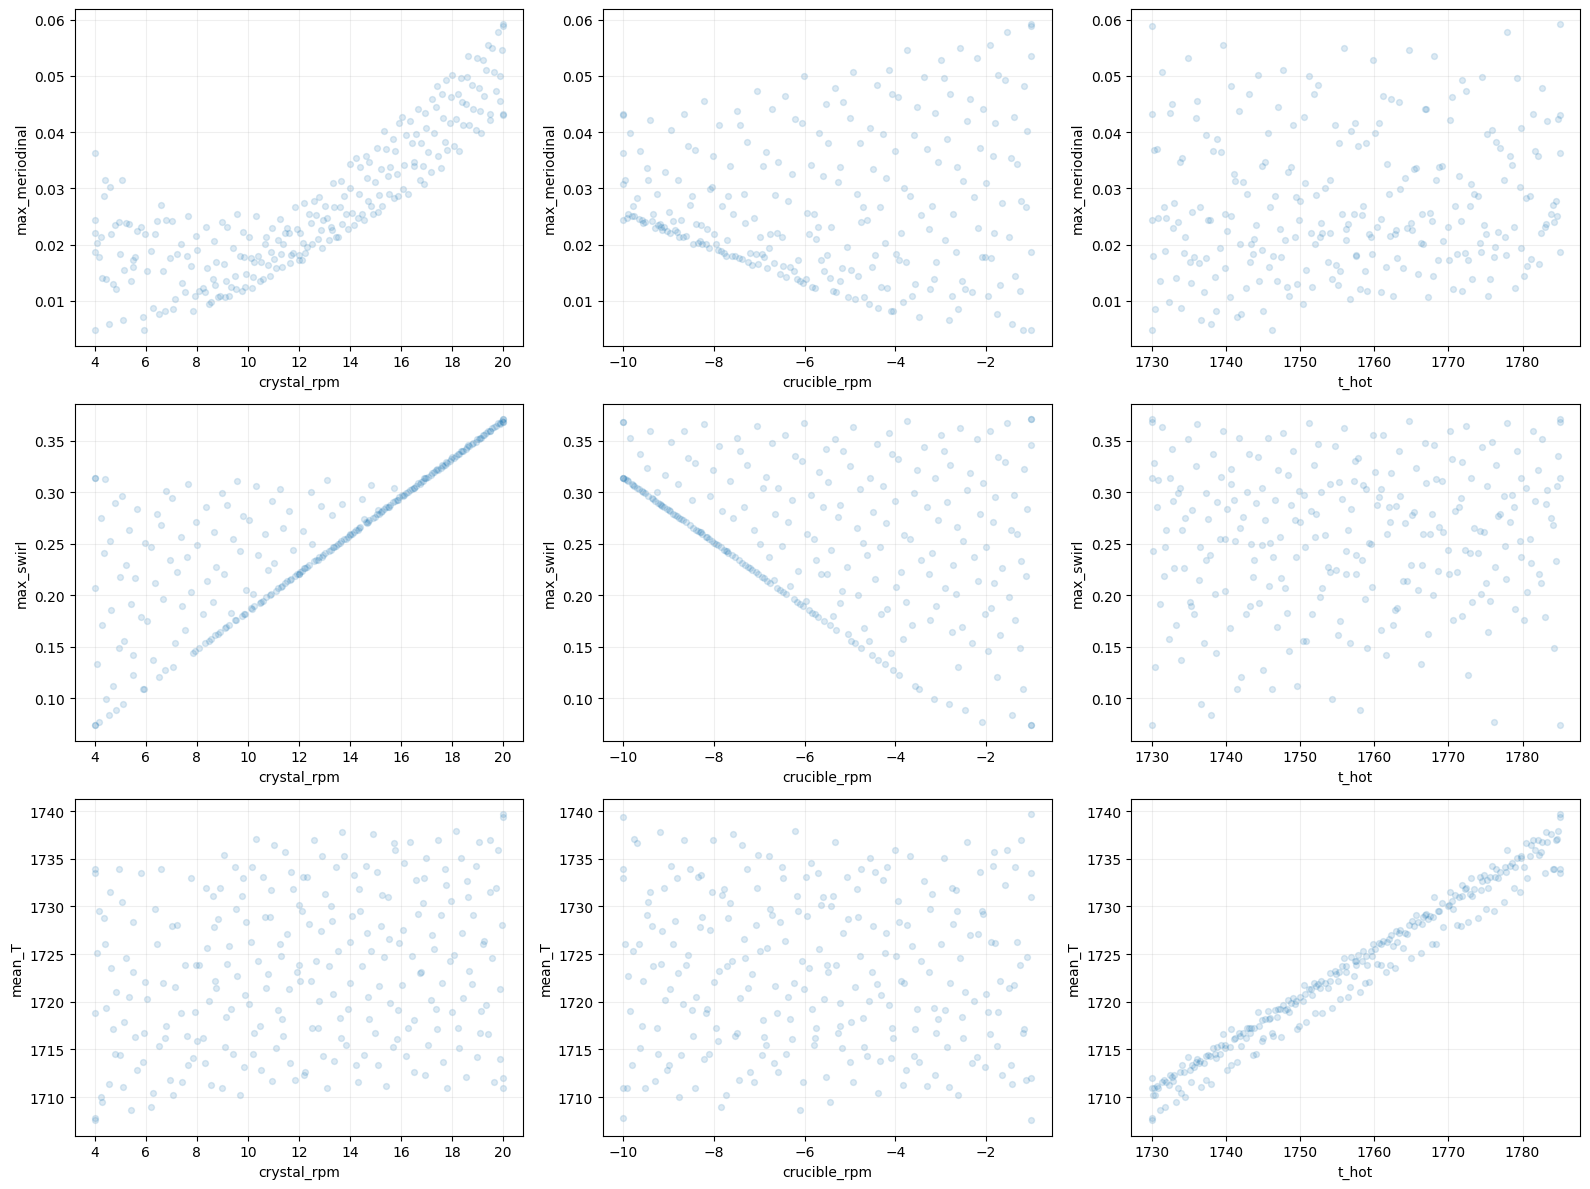

In [49]:
# Parameter versus QoI scatter plot

fig, axes = plt.subplots(3, 3, figsize=(16,12))

outputs = [
    "max_meriodinal",
    "max_swirl",
    "mean_T"
]

for i, output in enumerate(outputs):
    for j, parameter in enumerate(parameter_columns):

        ax = axes[i, j]

        ax.scatter(
            qoi_df[parameter],
            qoi_df[output],
            s=18,
            alpha=0.15
        )

        ax.set_ylabel(output)
        ax.set_xlabel(parameter)
        ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

## Correlation Analysis

In [50]:
# Spearman Correlatin analysis

corr = qoi_df[
    parameter_columns + qoi_columns
].corr(method="spearman")

corr.round(3)

,crystal_rpm,crucible_rpm,t_hot,max_meriodinal,rms_meriodinal,max_swirl,mean_T
crystal_rpm,1.000,0.052,0.045,0.816,0.756,0.794,0.182
crucible_rpm,0.052,1.000,-0.039,-0.019,-0.098,-0.319,-0.021
t_hot,0.045,-0.039,1.000,0.114,0.132,0.060,0.987
max_meriodinal,0.816,-0.019,0.114,1.000,0.979,0.911,0.196
rms_meriodinal,0.756,-0.098,0.132,0.979,1.000,0.931,0.205
max_swirl,0.794,-0.319,0.060,0.911,0.931,1.000,0.147
mean_T,0.182,-0.021,0.987,0.196,0.205,0.147,1.000


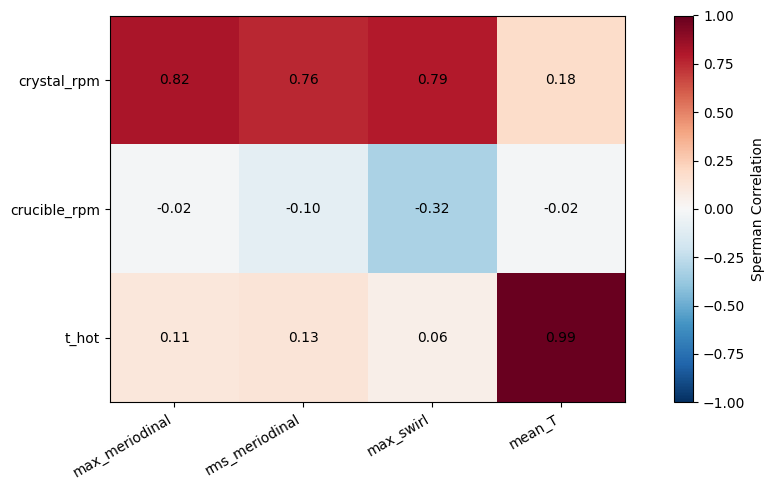

In [58]:
# Visualize the parameter correlation

input_output_corr = corr.loc[
    parameter_columns,
    qoi_columns
]

fig, ax = plt.subplots(figsize=(10, 5))

im = ax.imshow(
    input_output_corr,
    cmap="RdBu_r",
    vmin=-1,
    vmax=1
)

ax.set_xticks(range(len(qoi_columns)))
ax.set_xticklabels(qoi_columns, rotation=30, ha="right")

ax.set_yticks(range(len(parameter_columns)))
ax.set_yticklabels(parameter_columns)

for i in range(len(parameter_columns)):
    for j in range(len(qoi_columns)):

        ax.text(
            j, i,
            f"{input_output_corr.iloc[i,j]:0.2f}",
            ha="center",
            va="center"
        )

fig.colorbar(im, ax=ax, label="Sperman Correlation")

plt.tight_layout()
plt.show()

### Interpretation
The results reveal strong associations between crystal rotation and meridional velocity, and between wall temperature and mean nodal temperature.

The near-zero marginal correlation between crucible rotation and maximum meridional velocity is especially interesting. Our controlled corner comparison demonstrated that crucible rotation does affect the flow, but its effect changes depending on crystal rotation.

Low correlation does not mean low physical importance.

This is precisely why we should not use a simple correlation threshold to remove input features from our future ML dataset.

### Geometry Constraints

In [59]:
GEOMETRY = {
    "R_crucible": 0.30,
    "R_crystal": 0.18,
    "H_melt": 0.15,
    "T_crystal": 1685.0,
    "T_bottom_axis": 1700.0
}

print(GEOMETRY)

{'R_crucible': 0.3, 'R_crystal': 0.18, 'H_melt': 0.15, 'T_crystal': 1685.0, 'T_bottom_axis': 1700.0}


In [66]:
# boundary identification function

def identify_boundaries(pos,
                        geometry=GEOMETRY,
                        tol=1e-8):

    r = pos[:, 0]
    z = pos[:, 1]

    Rb = geometry["R_crucible"]
    Rc = geometry["R_crystal"]
    H = geometry["H_melt"]

    axis = np.isclose(r, 0, atol=tol, rtol=0)
    bottom = np.isclose(z, 0, atol=tol, rtol=0)
    wall = np.isclose(r, Rb, atol=tol, rtol=0)
    top = np.isclose(z, H, atol=tol, rtol=0)

    crystal = top & (r <= Rc + tol)
    lid = top & (r >= Rc - tol)

    boundary = axis | bottom | wall | crystal | lid

    interior = ~boundary

    return {
        "axis": axis,
        "bottom": bottom,
        "wall": wall,
        "crystal": crystal,
        "lid": lid,
        "interior": interior
    }

In [67]:
# Verify boundary identification

boundary_masks = identify_boundaries(pos)

for name, mask in boundary_masks.items():
    print(f"{name:12s}: {mask.sum():5d}")

axis        :    81
bottom      :   101
wall        :    81
crystal     :    57
lid         :    45
interior    :  7821


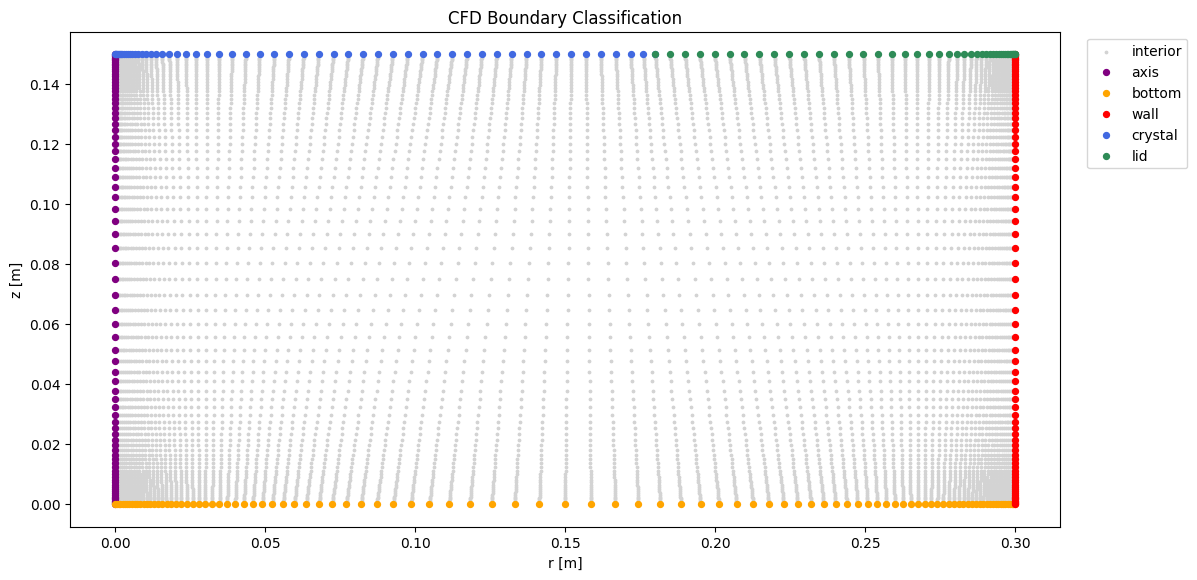

In [68]:
# Visualize the boundary 

boundary_colors = {
    "axis": "purple",
    "bottom": "orange",
    "wall": "red",
    "crystal": "royalblue",
    "lid": "seagreen",
    "interior": "lightgray"
}

fig, ax = plt.subplots(figsize=(12, 6))

for name in [
    "interior", "axis", "bottom", "wall", "crystal", "lid"
]:
    mask = boundary_masks[name]

    ax.scatter(
        pos[mask, 0],
        pos[mask, 1],
        s=3 if name == "interior" else 18,
        color=boundary_colors[name],
        label=name
    )
ax.set_xlabel("r [m]")
ax.set_ylabel("z [m]")
ax.set_title("CFD Boundary Classification")
ax.set_aspect("equal")
ax.legend(bbox_to_anchor=(1.02, 1))

plt.tight_layout()
plt.show()

In [70]:
# Calculate annalytical boundary conditions

def compute_boundary_conditions(
        pos, mu, geometry=GEOMETRY
):
    r = pos[:, 0]

    Rb = geometry["R_crucible"]
    Rc = geometry["R_crystal"]

    Tc = geometry["T_crystal"]
    T0 = geometry["T_bottom_axis"]

    wc = mu[0] * 2 * np.pi / 60
    wb = mu[1] * 2 * np.pi / 60
    Th = mu[2]

    masks = identify_boundaries(pos, geometry)

    # column order : u_r, u_z, u_swirl, p, T
    bc_values = np.zeros((len(pos), 5))
    bc_mask = np.zeros((len(pos), 5), dtype=bool)

    # All solid walls and prescribed lid
    solid = (
        masks["bottom"]   |
        masks["wall"]     |
        masks["crystal"]  |
        masks["lid"]
    )

    bc_mask[solid, 0:2] = True

    # crucible bototom
    m = masks["bottom"]

    bc_values[m, 2] = wb * r[m]
    bc_values[m, 4] = T0 + (Th - T0) * r[m] / Rb
    bc_mask[m, 2] = True
    bc_mask[m, 4] = True

    # cyrstal interface
    m = masks["crystal"]

    bc_values[m, 2] = wc * r[m]
    bc_values[m, 4] = Tc
    bc_mask[m, 2] = True
    bc_mask[m, 4] = True

    # outer melt lid
    m = masks["lid"]

    s = (r[m] - Rc) / (Rb - Rc)

    bc_values[m, 2] = (
        (1 - s) * wc * Rc +  s * wb * Rb
    )

    bc_values[m, 4] = (1 - s) * Tc + s * Th

    bc_mask[m, 2] = True
    bc_mask[m, 4] = True

    # symmetry axis
    m = masks["axis"]

    bc_values[m, 0] = 0
    bc_values[m, 2] = 0

    bc_mask[m, 0] = True
    bc_mask[m, 2] = True

    # pressure reference at the origin
    m = masks["axis"] & masks["bottom"]

    bc_values[m, 3] = 0
    bc_mask[m, 3] = True

    return bc_values, bc_mask

In [71]:
# function testing

bc_values, bc_mask = compute_boundary_conditions(pos, mu)

print("BC vlaues shape:", bc_values.shape)
print("BC Mask shape:", bc_mask.shape)

print("Prescribed values per field:")

for i, field in enumerate(field_columns):
    print(field, bc_mask[:, i].sum())

BC vlaues shape: (8181, 5)
BC Mask shape: (8181, 5)
Prescribed values per field:
u_r 360
u_z 281
u_swirl 281
p 1
T 202


### Validate analytical conditions against CFD data

In [72]:
# calculate boundary condition residuals

records = []

for i, field in enumerate(field_columns):
    mask = bc_mask[:, 1]

    actual = y[mask, 1]
    prescribed = bc_values[mask, 1]

    error = actual - prescribed

    records.append({
        "field": field,
        "num_nodes": mask.sum(),
        "MAE": np.mean(np.abs(error)),
        "RMSE": np.sqrt(np.mean(error**2)),
        "max_error": np.max(np.abs(error))
    })

bc_validation = pd.DataFrame(records)

bc_validation

,field,num_nodes,MAE,RMSE,max_error
0,u_r,281,0.0,0.0,0.0
1,u_z,281,0.0,0.0,0.0
2,u_swirl,281,0.0,0.0,0.0
3,p,281,0.0,0.0,0.0
4,T,281,0.0,0.0,0.0


### Visualize the boundary condition agreement

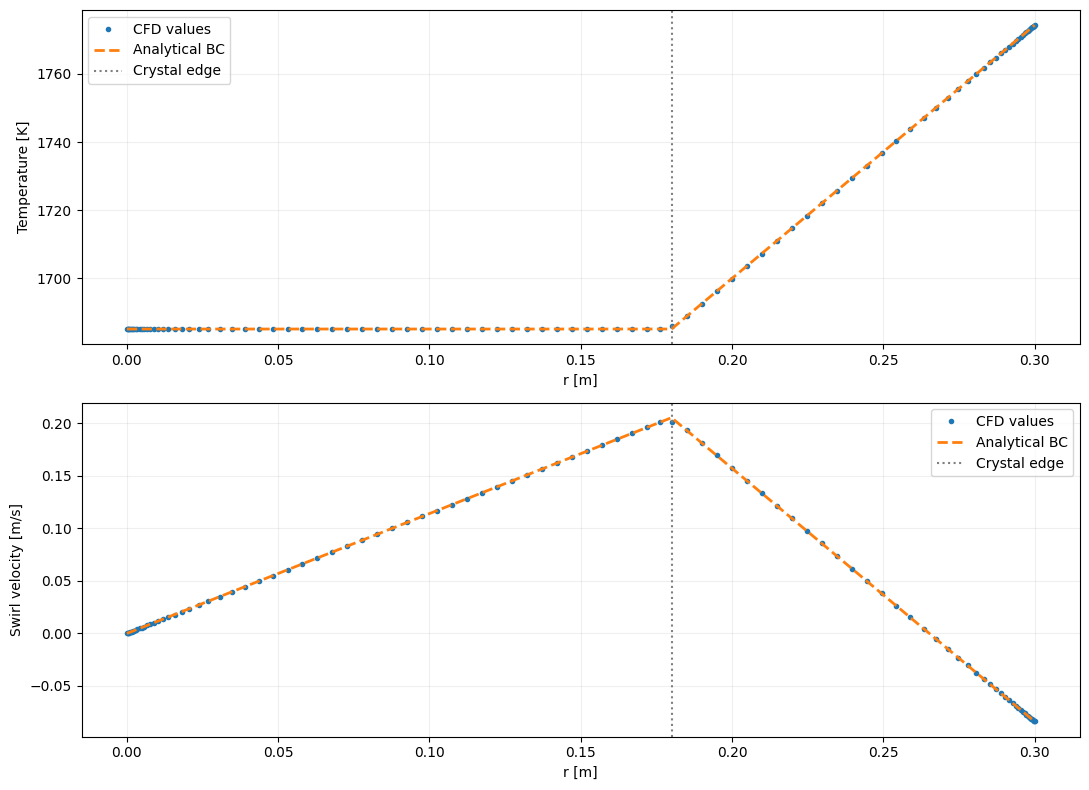

In [73]:
# Temperature adn swirl boundary profiles

top_mask = (
    boundary_masks["crystal"] | boundary_masks["lid"]
)

indices = np.flatnonzero(top_mask)

indices = indices[
    np.argsort(pos[indices, 0])
]

fig, axes = plt.subplots(2, 1, figsize=(11, 8))

for ax, col, label in [
    (axes[0], 4, "Temperature [K]"),
    (axes[1], 2, "Swirl velocity [m/s]")
]:
    ax.plot(
        pos[indices, 0],
        y[indices, col],
        "o",
        markersize=3,
        label="CFD values"
    )

    ax.plot(
        pos[indices, 0],
        bc_values[indices, col],
        "--",
        linewidth=2,
        label="Analytical BC"
    )

    ax.axvline(
        GEOMETRY["R_crystal"],
        color="grey",
        linestyle=":",
        label="Crystal edge"
    )

    ax.set_xlabel("r [m]")
    ax.set_ylabel(label)
    ax.legend()
    ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

### Encode boundary types for ML

In [74]:
# Construct boundary features
boundary_names = [
    "axis",
    "bottom",
    "wall",
    "crystal",
    "lid"
]

boundary_features = np.column_stack([
    boundary_masks[name] for name in boundary_names
]).astype(np.float32)

print(boundary_features.shape)

(8181, 5)


In [75]:
# calcualte distance features

def compute_distance_features(
        pos, geometry=GEOMETRY
):
    r = pos[:, 0]
    z = pos[:, 1]

    Rb = geometry["R_crucible"]
    Rc = geometry["R_crystal"]
    H = geometry["H_melt"]

    d_axis = r
    d_bottom = z

    d_wall = Rb - r

    d_crystal = np.hypot(
        np.maximum(r - Rc, 0),
        H - z
    )

    d_lid = np.hypot(
        np.maximum(Rc - r, 0),
        H - z
    )

    return np.column_stack([
        d_axis,
        d_bottom,
        d_wall,
        d_crystal,
        d_lid
    ])

In [76]:
distance_features = compute_distance_features(pos)

print(distance_features.shape)

(8181, 5)


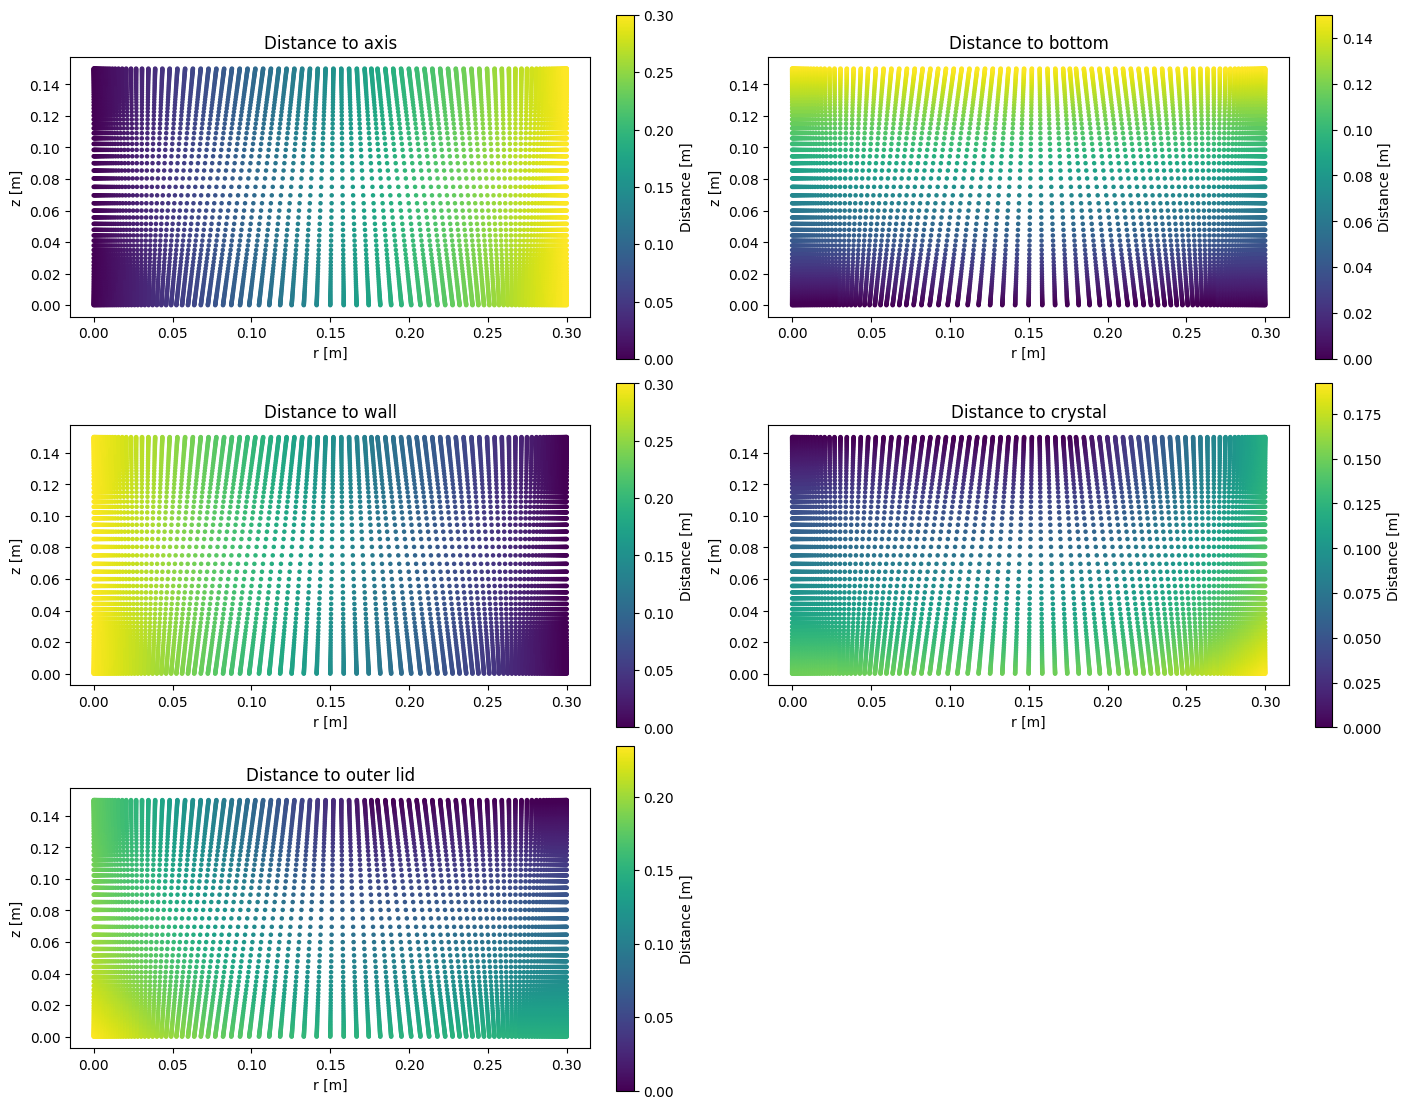

In [77]:
# Geometry distance visualization

distance_names = [
    "Distance to axis",
    "Distance to bottom",
    "Distance to wall",
    "Distance to crystal",
    "Distance to outer lid"
]

fig, axes = plt.subplots(
    3, 2, figsize=(14, 11),
    constrained_layout=True
)

for i, ax in enumerate(axes.flat[:5]):

    sc = ax.scatter(
        pos[:, 0],
        pos[:, 1],
        c=distance_features[:, i],
        s=5,
        cmap="viridis"
    )

    ax.set_title(distance_names[i])
    ax.set_xlabel("r [m]")
    ax.set_ylabel("z [m]")
    ax.set_aspect("equal")

    fig.colorbar(sc, ax=ax, label="Distance [m]")

axes.flat[-1].axis("off")

plt.show()